# EDA · ¿Cuán lejos está el aire porteño de las guías de la OMS?

**TP integrador de Análisis de Datos.** Rol: equipo de datos de una agencia de calidad ambiental que informa a
funcionarios, prensa y ciudadanía.

**Pregunta:** ¿cuán lejos está la calidad del aire de la Ciudad de Buenos Aires de las guías de la OMS (2021), y cómo
varía esa brecha entre estaciones, contaminantes, tipo de día y período?

| Subpregunta | Sección |
|---|---|
| 1. ¿Qué % de días se supera la guía diaria, por estación y contaminante? | 5 |
| 2. ¿Cuántas veces por encima de la guía anual están los promedios anuales? | 6 |
| 3. ¿Qué estación está peor y con qué contaminante? | 5, 6 |
| 4. ¿Cambia el cumplimiento entre hábiles, sábados, domingos y feriados? | 7, 8 |
| 5. ¿Hay estacionalidad? | 4, 7 |
| 6. ¿Cuánto condiciona la calidad de los datos a las conclusiones? | 2, 10 |

**Hipótesis:**
- **H1:** el NO₂ es el contaminante más crítico: el que más se aleja de las guías de la OMS.
- **H2:** Córdoba, la estación ubicada sobre una avenida de tránsito intenso, es la más comprometida en NO₂.
- **H3:** los domingos y feriados la brecha se reduce de forma visible.

Las tres salen de una misma premisa: **en la Ciudad, el NO₂ proviene sobre todo del tránsito**. H1 la aplica al
contaminante (además, la OMS 2021 endureció la guía anual de NO₂ de 40 a 10 µg/m³), H2 a la estación (la APrA
describe a Córdoba con flujo vehicular alto) y H3 al tipo de día (efecto fin de semana). La fundamentación completa,
con fuentes, está en el README ("De dónde salen las hipótesis").

**Los escalones de la OMS.** La guía (AQG) es el nivel sin riesgo apreciable para la salud y es muy exigente. Por
eso la OMS define **objetivos intermedios** (IT1 el menos exigente … IT4 el más cercano a la guía) para medir el
avance. Para el NO₂: guía diaria 25 µg/m³, IT2 50, IT1 120; guía anual 10, IT3 20, IT2 30, IT1 40.

**De dónde salen los datos.** Este notebook lee la capa **gold** que el ETL (`python -m src.etl`) exporta a
`data/final/` a partir del CSV horario de calidad del aire de BA Data: el modelo estrella (dimensiones,
`fact_medicion_diaria` y `fact_medicion_horaria`), las guías de la OMS (`guia_oms`), los indicadores anuales
(`agg_anual`) y el resumen de calidad (`calidad_resumen`). No recalcula reglas de negocio: las reglas viven en SQL
(dbt: bronze → silver → gold) y acá se exploran y se grafican.
Todas las concentraciones se muestran en la unidad de la guía OMS (µg/m³; mg/m³ para el CO).

In [1]:
import logging
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # avisos de fuentes de Sweetviz

# Raíz del repo: funciona corriendo el notebook desde notebooks/ o desde la raíz
RAIZ = Path.cwd() if (Path.cwd() / "data" / "final").exists() else Path.cwd().parent
FINAL = RAIZ / "data" / "final"
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# --- Estilo de los gráficos -----------------------------------------------------------------
# Superficie clara, tinta oscura, grilla tenue. Una estación = un color fijo en todo el TP
# (paleta validada para daltonismo). Los textos nunca van en el color de la serie.
SUPERFICIE, TINTA, TINTA_2, TENUE, GRILLA, EJE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLOR_ESTACION = {"centenario": "#2a78d6", "cordoba": "#eb6834", "la_boca": "#1baf7a"}
# Niveles OMS: escala ordinal de un solo tono (más oscuro = más lejos de la guía) + gris para "cumple"
COLOR_NIVEL = {"AQG": "#c3c2b7", "IT4": "#86b6ef", "IT3": "#5598e7", "IT2": "#2a78d6", "IT1": "#1c5cab", "> IT1": "#0d366b"}

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TINTA, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def coma(x, dec=1):
    # Número con coma decimal (formato argentino) para etiquetas
    return f"{x:.{dec}f}".replace(".", ",")


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")
    print(f"Figura guardada: reports/figures/{nombre}.png")


def linea_guia(ax, valor, texto, estilo="--", color=TINTA_2, horizontal=True, lado="derecha", debajo=False):
    # Línea de referencia OMS con su etiqueta (siempre visible en los gráficos).
    # lado / debajo: dónde va la etiqueta, para que no tape los datos.
    if horizontal:
        ax.axhline(valor, color=color, linestyle=estilo, linewidth=1.2, zorder=3)
        x, ha, dx = (1, "right", -4) if lado == "derecha" else (0, "left", 4)
        ax.annotate(texto, xy=(x, valor), xycoords=("axes fraction", "data"), xytext=(dx, -4 if debajo else 4),
                    textcoords="offset points", ha=ha, va="top" if debajo else "bottom", fontsize=8.5, color=color,
                    bbox=dict(facecolor=SUPERFICIE, edgecolor="none", alpha=0.85, pad=1))
    else:
        ax.axvline(valor, color=color, linestyle=estilo, linewidth=1.2, zorder=3)
        ax.annotate(texto, xy=(valor, 1), xycoords=("data", "axes fraction"), xytext=(3, -2),
                    textcoords="offset points", ha="left", va="top", fontsize=8.5, color=color, rotation=90,
                    bbox=dict(facecolor=SUPERFICIE, edgecolor="none", alpha=0.85, pad=1))

In [2]:
# Tablas finales del ETL. El CSV no guarda tipos: pandas deduce números y booleanos, y las fechas se convierten acá.
def leer(nombre):
    tabla = pd.read_csv(FINAL / f"{nombre}.csv", low_memory=False)
    for col in ("fecha", "anio_mes"):
        if col in tabla:
            tabla[col] = pd.to_datetime(tabla[col])
    return tabla


dim_estacion = leer("dim_estacion")
dim_calendario = leer("dim_calendario")
guia_oms = leer("guia_oms")                 # guía y objetivos intermedios de la OMS (una fila por nivel)
fact = leer("fact_medicion_diaria")         # grilla completa: fecha × estación × contaminante
horaria = leer("fact_medicion_horaria")     # NO2 hora por hora (segunda tabla de hechos)
agg_anual = leer("agg_anual")               # indicadores por año (2010-2026) y últimos 12 meses
calidad_resumen = leer("calidad_resumen")   # qué pasó con cada valor horario del período

# Días con dato, con el valor en la unidad de la guía OMS (µg/m³; mg/m³ el CO)
diario = fact[fact.tiene_dato].drop(columns="valor").rename(columns={"valor_masa": "valor"})
# Indicadores del período de estudio (2024, 2025, 2026 parcial y últimos 12 meses)
anual = agg_anual[agg_anual.es_periodo_estudio].copy()
# Serie larga 2010-2025 (contexto): años completos, NO2 y PM10
contexto = agg_anual[(agg_anual.tipo_periodo == "anio_completo") & (agg_anual.anio <= 2025)
                     & agg_anual.id_contaminante.isin(["no2", "pm10"])].astype({"anio": int})

NOMBRE = dim_estacion.set_index("id_estacion")["nombre"].to_dict()
ORDEN_ESTACIONES = dim_estacion.sort_values("orden")["id_estacion"].tolist()
GUIA = {(r.id_contaminante, r.promedio): r.umbral for r in guia_oms[guia_oms.nivel == "AQG"].itertuples()}
# Umbrales de 24 h por nivel: los gráficos los toman de la tabla de la OMS, no se escriben a mano
NIVEL_24H = {(r.id_contaminante, r.nivel): r.umbral for r in guia_oms[guia_oms.promedio == "24h"].itertuples()}
GUIA_NO2, GUIA_PM10, GUIA_CO = (GUIA[(c, "24h")] for c in ("no2", "pm10", "co"))
for nombre, df in [("fact_medicion_diaria", fact), ("fact_medicion_horaria", horaria), ("agg_anual", agg_anual)]:
    print(f"{nombre:25s} {df.shape[0]:>7,} filas × {df.shape[1]} columnas".replace(",", "."))

fact_medicion_diaria        9.036 filas × 12 columnas
fact_medicion_horaria      70.704 filas × 7 columnas
agg_anual                     162 filas × 31 columnas


## 1. Estructura y tipos

**Qué se busca:** entender la granularidad y los tipos antes de calcular nada.

El crudo (`data/raw/calidad-aire.csv`, dataset "Calidad del aire" de BA Data) viene en formato **ancho**:
**147.470 filas**, una por fecha y hora desde octubre de 2009, y una columna por estación × contaminante (CO, NO₂ y
PM10 de Centenario, Córdoba y La Boca; las de Palermo vienen vacías). Todo como texto. Cada contaminante se publica
con un promedio distinto: **NO₂ horario**, **CO móvil de 8 h** y **PM10 móvil de 24 h**.

El ETL lo pasa a formato largo (una fila por fecha × hora × estación × contaminante), aplica las reglas de calidad a
cada hora y arma el **promedio de 24 h** de cada día, que es el que compara la OMS. La fact diaria es una **grilla
completa** del período (1.004 días × 3 estaciones × 3 contaminantes = 9.036 filas): los días sin dato existen y
llevan `tiene_dato = False` y el motivo. Una segunda tabla de hechos, `fact_medicion_horaria`, guarda las horas de
NO₂ (70.704 filas) para el perfil horario.

In [3]:
print(fact.dtypes.to_string())
fact.head()

fecha              datetime64[us]
id_estacion                   str
id_contaminante               str
n_horas_validas             int64
tiene_dato                   bool
motivo_sin_dato               str
valor                     float64
valor_masa                float64
supera_guia                object
nivel_oms                     str
orden_nivel_oms           float64
es_outlier                   bool


,fecha,id_estacion,id_contaminante,n_horas_validas,tiene_dato,motivo_sin_dato,valor,valor_masa,supera_guia,nivel_oms,orden_nivel_oms,es_outlier
0,2024-01-01,centenario,co,24,True,NaN,0.193,0.221,False,AQG,1.0,False
1,2024-01-01,centenario,no2,24,True,NaN,7.790,14.658,False,AQG,1.0,False
2,2024-01-01,centenario,pm10,24,True,NaN,9.000,9.000,False,AQG,1.0,False
3,2024-01-01,cordoba,co,0,False,sin_dato_fuente,NaN,NaN,NaN,NaN,NaN,False
4,2024-01-01,cordoba,no2,0,False,sin_dato_fuente,NaN,NaN,NaN,NaN,NaN,False


In [4]:
# Variables categóricas: cuántas filas hay de cada valor
for col in ["id_estacion", "id_contaminante", "motivo_sin_dato"]:
    print(fact[col].value_counts(dropna=False).rename_axis(col).to_frame("filas").T, "\n")

id_estacion  centenario  cordoba  la_boca
filas              3012     3012     3012 

id_contaminante    co   no2  pm10
filas            3012  3012  3012 

motivo_sin_dato   NaN  sin_dato_fuente  incompleto  sin_fila
filas            7615              910         457        54 



In [5]:
# Variables numéricas: valor en unidad original y en la unidad de la OMS, por contaminante (solo datos válidos)
(fact[fact.tiene_dato]
    .groupby("id_contaminante")[["valor", "valor_masa"]]
    .describe(percentiles=[.25, .5, .75, .99]).round(2))

valor                                                       valor_masa                                                        
                  count   mean   std   min    25%    50%    75%    99%    max      count   mean    std   min    25%    50%    75%    99%     max
id_contaminante                                                                                                                                 
co               2562.0   0.47  0.23  0.05   0.30   0.42   0.58   1.19   1.68     2562.0   0.53   0.26  0.06   0.35   0.48   0.66   1.36    1.92
no2              2440.0  21.00  9.19  4.17  14.39  19.15  25.87  48.24  65.78     2440.0  39.51  17.29  7.85  27.07  36.03  48.68  90.77  123.77
pm10             2613.0  23.36  9.96  0.00  17.00  21.00  28.00  55.88  99.00     2613.0  23.36   9.96  0.00  17.00  21.00  28.00  55.88   99.00

In [6]:
# Calendario: tipos de día del período (los feriados tienen prioridad sobre sábado/domingo)
dim_calendario.groupby(["tipo_dia_etiqueta"]).size().rename("días").to_frame().T

tipo_dia_etiqueta,Domingo,Feriado,Hábil,Sábado
días,138,53,674,139


### 1.1 Perfil automático con Sweetviz

**Sweetviz** genera un reporte HTML con el perfil de cada variable (tipo, nulos, distribución, valores frecuentes) y
las asociaciones entre variables. Es un primer barrido rápido; después el EDA guiado por las preguntas profundiza.

Se corre sobre una tabla **ancha**: una fila por estación y día, una columna por contaminante (promedio de 24 h, en
µg/m³; CO en mg/m³). Sobre la fact en formato largo no tendría sentido, porque mezclaría contaminantes en una
misma columna. Se generan dos reportes en `reports/`:
- `sweetviz_perfil.html`: perfil de todas las variables.
- `sweetviz_habil_vs_no_habil.html`: compara días hábiles contra sábados, domingos y feriados, con el NO₂ como
  variable objetivo (insumo para H3). Sweetviz no acepta nulos en la variable objetivo: solo entran días con NO₂.

In [7]:
import sweetviz as sv

ancho_sv = (fact
            .pivot_table(index=["id_estacion", "fecha"], columns="id_contaminante", values="valor_masa")
            .reset_index()
            .merge(dim_calendario[["fecha", "tipo_dia", "estacion_del_anio", "mes"]], on="fecha"))
ancho_sv["estacion"] = ancho_sv["id_estacion"].map(NOMBRE)
ancho_sv = ancho_sv[["estacion", "tipo_dia", "estacion_del_anio", "mes", "no2", "pm10", "co"]]

# rc_context: Sweetviz cambia la configuración de matplotlib (fuentes); así se restaura al terminar
with plt.rc_context():
    perfil = sv.analyze(ancho_sv)
    perfil.show_html(str(RAIZ / "reports" / "sweetviz_perfil.html"), open_browser=False, layout="vertical")

    con_no2 = ancho_sv.dropna(subset=["no2"])
    comparacion = sv.compare_intra(con_no2, con_no2["tipo_dia"] == "habil", ["Hábil", "Sábado, domingo o feriado"],
                                   target_feat="no2")
    comparacion.show_html(str(RAIZ / "reports" / "sweetviz_habil_vs_no_habil.html"), open_browser=False,
                          layout="vertical")

/home/user/nox-ciudad/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


                                             |          | [  0%]   00:00 -> (? left)

[Summarizing dataframe]                      |          | [  0%]   00:00 -> (? left)

Feature: estacion                            |█▎        | [ 12%]   00:00 -> (00:00 left)

Feature: estacion                            |██▌       | [ 25%]   00:00 -> (00:01 left)

Feature: tipo_dia                            |██▌       | [ 25%]   00:00 -> (00:01 left)

... (39 outputs left out)

Done! Use 'show' commands to display/save.   |          | [  0%]   00:00 -> (? left)

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:00 -> (00:00 left)

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:00 -> (00:00 left)

Report /home/user/nox-ciudad/reports/sweetviz_habil_vs_no_habil.html was generated.


**Qué muestra Sweetviz y qué no:** confirma los tipos, la proporción de nulos por contaminante, las distribuciones
asimétricas y la asociación entre contaminantes. En la comparación, los días no hábiles tienen menos NO₂. Lo que
**no** sabe es el dominio: no conoce la guía de la OMS, la regla del 75% ni cómo se arma el promedio diario a partir
de horas y promedios móviles. Por eso el resto del EDA se hace a mano, guiado por las subpreguntas.

**Qué se concluye:**
- Las fechas ya son `datetime64` y los valores, `float`: la conversión de texto (fecha como `12FEB2011:00:00:00`, `s/d`,
  `#REF!`, `<0.05`) se hizo en SQL, en la capa silver. Los identificadores quedaron en snake_case y sin tildes (`la_boca`, `no2`).
- Hay **variables categóricas** (estación, contaminante, tipo de día, estación del año) y **numéricas**
  (concentraciones, horas válidas por día), además de dos **series temporales** (diaria y horaria).
- `motivo_sin_dato` está vacía en los días con dato: es un **nulo estructural** ("no aplica"), no un dato
  faltante. Los días sin dato sí son faltantes y por eso se cuentan en la completitud.

## 2. Calidad de los datos

**Qué se busca:** saber cuánto dato hay, qué se descartó y por qué, antes de sacar conclusiones (subpregunta 6).

### 2.1 Qué pasó con cada valor horario del período

In [8]:
tabla = (calidad_resumen.pivot_table(index="categoria", columns="id_contaminante", values="n_valores",
                                     aggfunc="sum", fill_value=0)
         [["no2", "pm10", "co"]])
tabla["total"] = tabla.sum(axis=1)
tabla.sort_values("total", ascending=False)

id_contaminante,no2,pm10,co,total
categoria,,,,
valido,59902,63198,63509,186609
sin_dato_fuente,10715,7431,7118,25264
hora_invalida,108,108,108,324
texto_invalido,83,72,72,227
fila_en_cero,3,3,3,9
fuera_de_rango,1,0,2,3


- **88% de los valores horarios del período son válidos**; 11,9% son `s/d` o celdas vacías en la fuente. En el
  período no hay valores bajo el límite de detección (`<0.05`, que se imputan como **límite / 2**): aparecen solo en
  el CO de 2010 a 2017.
- Las reglas de validación descartan **0,3%**: las celdas de **36 filas con hora 0** (todas vacías; el día va de la
  hora 1 a la 24) y **227 textos que no son números**, más un puñado de valores imposibles (sección 2.3).

### 2.2 Completitud por estación × contaminante × mes

Es el gráfico central de calidad: muestra qué meses no tienen datos y, por la **regla del 75%**, qué indicadores
anuales no se pueden calcular.

Figura guardada: reports/figures/01_completitud_heatmap.png


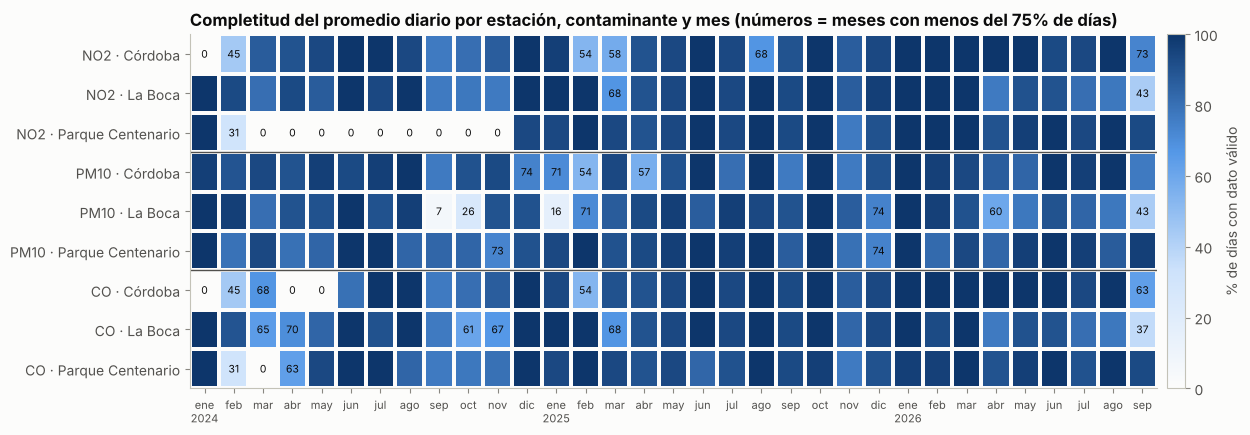

In [9]:
import yaml

# El umbral del 75% sale de las variables de dbt (dbt_project.yml), no se escribe acá
UMBRAL = yaml.safe_load((RAIZ / "dbt" / "dbt_project.yml").read_text(encoding="utf-8"))["vars"]["umbral_completitud"]
# Completitud mensual = proporción de días con dato válido (la fact tiene todos los días, con o sin dato)
cm = (fact.assign(anio_mes=fact.fecha.dt.to_period("M").dt.to_timestamp())
      .groupby(["id_contaminante", "id_estacion", "anio_mes"])["tiene_dato"].mean()
      .rename("completitud").reset_index())
cm["cumple_umbral"] = cm.completitud >= UMBRAL
cm["fila"] = cm.id_contaminante.str.upper() + " · " + cm.id_estacion.map(NOMBRE)
orden_filas = [f"{c} · {NOMBRE[e]}" for c in ["NO2", "PM10", "CO"] for e in ORDEN_ESTACIONES]
matriz = cm.pivot(index="fila", columns="anio_mes", values="completitud").loc[orden_filas]
cumple = cm.pivot(index="fila", columns="anio_mes", values="cumple_umbral").loc[orden_filas]

fig, ax = plt.subplots(figsize=(13, 4.6))
cmap = LinearSegmentedColormap.from_list("completitud", ["#fcfcfb", "#cde2fb", "#5598e7", "#0d366b"])
malla = ax.pcolormesh(matriz.values * 100, cmap=cmap, vmin=0, vmax=100, edgecolors=SUPERFICIE, linewidth=1.5)
ax.set_yticks(np.arange(len(matriz)) + 0.5, matriz.index)
ax.invert_yaxis()
meses = pd.to_datetime(matriz.columns)
MES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
ax.set_xticks(np.arange(len(meses)) + 0.5,
              [f"{MES[m.month - 1]}\n{m.year}" if m.month == 1 else MES[m.month - 1] for m in meses], fontsize=8)
ax.grid(False)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.values[i, j]
        if not cumple.values[i, j]:  # solo se rotulan los meses que no cumplen el 75%
            ax.text(j + 0.5, i + 0.5, f"{v*100:.0f}", ha="center", va="center", fontsize=7.5, color=TINTA)
for k in (3, 6):
    ax.axhline(k, color=TINTA_2, linewidth=1)
barra = fig.colorbar(malla, ax=ax, pad=0.01, fraction=0.03)
barra.set_label("% de días con dato válido")
ax.set_title("Completitud del promedio diario por estación, contaminante y mes "
             "(números = meses con menos del 75% de días)")
guardar(fig, "01_completitud_heatmap")
plt.show()

In [10]:
# Qué indicadores anuales deja afuera la regla del 75%
anual.loc[~anual.es_valido, ["id_estacion", "id_contaminante", "periodo", "n_dias_con_dato", "completitud"]]

,id_estacion,id_contaminante,periodo,n_dias_con_dato,completitud
32,centenario,no2,2024,69,0.1885
68,cordoba,co,2024,225,0.6148


**Lo que queda afuera y por qué:**
- **NO₂ de Parque Centenario en 2024** (19% de días): la estación no tiene NO₂ de marzo a noviembre de 2024 (tampoco
  en los informes mensuales en PDF de la APrA). No hay promedio anual válido de Centenario para 2024.
- **CO de Córdoba en 2024** (62%): faltan enero, abril y mayo.
- Otros huecos que no alcanzan para invalidar el año: PM10 de La Boca (septiembre y octubre de 2024 y enero de 2025
  casi vacíos), NO₂ de Córdoba (enero y febrero de 2024, febrero y marzo de 2025) y septiembre de 2026 en La Boca
  (43%).
- **Días sin ninguna hora en la fuente:** 6 (20 y 21/09/2024, 19/10/2024 y 31/03 a 02/04/2025). El resto de los huecos
  es por contaminante o por días que la fuente trae incompletos.

### 2.3 Reglas de validación sobre los valores horarios

In [11]:
# SQL directo sobre los CSV con DuckDB: valores descartados por regla, con las fechas en que aparecen
resumen_csv = (FINAL / "calidad_resumen.csv").as_posix()
print(duckdb.sql(f'''
    select categoria as regla, id_contaminante, n_valores as valores, n_dias as dias,
           primera_fecha as primera, ultima_fecha as ultima
    from '{resumen_csv}'
    where categoria not in ('valido', 'sin_dato_fuente')
    order by regla, id_contaminante
''').df().to_string(index=False))

         regla id_contaminante  valores  dias    primera     ultima
  fila_en_cero              co        3     1 2025-09-17 2025-09-17
  fila_en_cero             no2        3     1 2025-09-17 2025-09-17
  fila_en_cero            pm10        3     1 2025-09-17 2025-09-17
fuera_de_rango              co        2     1 2026-06-01 2026-06-01
fuera_de_rango             no2        1     1 2025-08-13 2025-08-13
 hora_invalida              co      108    36 2024-02-15 2026-09-15
 hora_invalida             no2      108    36 2024-02-15 2026-09-15
 hora_invalida            pm10      108    36 2024-02-15 2026-09-15
texto_invalido              co       72     2 2024-05-17 2024-05-18
texto_invalido             no2       83     3 2024-05-17 2025-12-01
texto_invalido            pm10       72     2 2024-05-17 2024-05-18


- **`#REF!`** (17 y 18/05/2024, en todas las columnas): un error de fórmula de la planilla de origen que llegó al CSV
  publicado. **`x/d`** (01/12/2025, NO₂ de La Boca): un tipeo de `s/d`.
- **Fila en cero** (17/09/2025 a las 12 h): todas las mediciones de esa hora valen 0, en las tres estaciones a la vez.
  Es una hora vacía cargada con ceros, no aire limpio.
- **Fuera de rango:** NO₂ de −2 ppb en Centenario (13/08/2025) y CO de 23 ppm en La Boca (01/06/2026, a las 6 y 7 h)
  con las horas vecinas en 0,8 ppm: un error de carga (el máximo válido del período es 2,9 ppm).
- **Valor trabado** (NO₂ idéntico 10 horas seguidas o más): no aparece en el período, pero sí en la serie histórica
  que se usa como contexto (sección 11).
- Ninguna regla descarta un día entero por sí sola: lo que pesa en la completitud son los `s/d` y los días que la
  fuente trae incompletos.

### 2.4 De horas a días

El promedio de 24 h se arma distinto según cómo publica la red cada contaminante:
- **NO₂ (horario):** promedio de las horas válidas, solo si hay **al menos 18 de 24** (75%, el criterio de la Directiva
  europea 2008/50/CE para pasar de horas a día). Con menos, el día queda como `incompleto`.
- **PM10 (móvil de 24 h):** el valor de la hora 24, que ya es el promedio de 00 a 24.
- **CO (móvil de 8 h):** el promedio de las horas 8, 16 y 24 (los tres bloques de 8 h del día).

In [12]:
# Cuántas horas válidas tiene cada día de NO2 (la regla de 18 horas, en números)
no2_dias = fact[fact.id_contaminante == "no2"]
tramos = pd.cut(no2_dias.n_horas_validas, [-1, 0, 17, 23, 24],
                labels=["ninguna", "1 a 17 (no alcanza)", "18 a 23 (se calcula)", "24"])
pd.crosstab(no2_dias.id_estacion.map(NOMBRE), tramos, margins=True, margins_name="Total")

n_horas_validas,ninguna,1 a 17 (no alcanza),18 a 23 (se calcula),24,Total
id_estacion,,,,,
Córdoba,85,55,63,801,1004
La Boca,43,61,86,814,1004
Parque Centenario,302,26,71,605,1004
Total,430,142,220,2220,3012


**Qué se concluye:**
- La mayoría de los días de NO₂ tiene las 24 horas (80% en Córdoba y La Boca; 60% en Centenario, que no midió de marzo
  a noviembre de 2024). La regla de 18 horas deja afuera entre 26 y 61 días por estación (2,6% a 6,1%).
- Muchos de esos días incompletos vienen de **cortes de la exportación**: la fuente trae pares de días cortados al
  mediodía (un día con las horas 1 a 12 y el siguiente con las 13 a 24) que sí tienen dato en los informes mensuales
  en PDF de la APrA.
- **Validación externa:** el promedio diario armado así coincide con el publicado en esos informes en PDF (2024 a
  2026) en el **94% de los días para el NO₂, el 97% para el CO y el 98% para el PM10**; con una tolerancia de ±1
  unidad (redondeo), entre el 98,8% y el 99,6%.

### 2.5 Valores atípicos (outliers)

Criterio: promedio diario > Q3 + 3·IQR de su estación × contaminante. **Se marcan, no se borran.**

In [13]:
# Outliers: la fact los marca (es_outlier = valor > Q3 + 3·IQR de su estación × contaminante); no los borra.
# Para leerlos se compara cada uno con la mediana de su estación × contaminante (unidad original).
mediana = fact[fact.tiene_dato].groupby(["id_estacion", "id_contaminante"])["valor"].median().rename("mediana")
outliers = (fact[fact.es_outlier]
            .join(mediana, on=["id_estacion", "id_contaminante"])
            .merge(dim_calendario[["fecha", "nombre_dia"]], on="fecha"))
outliers["veces_mediana"] = (outliers.valor / outliers.mediana).round(1)
print(outliers.groupby("id_contaminante").size().rename("outliers").to_frame().T.to_string())
# ¿El mismo día es atípico en varias estaciones? Entonces es un episodio atmosférico, no un error de un equipo.
(outliers
    .groupby(["fecha", "id_contaminante"])
    .agg(estaciones=("id_estacion", "nunique"), max_veces_mediana=("veces_mediana", "max"))
    .query("estaciones >= 2").sort_values(["estaciones", "max_veces_mediana"], ascending=False).head(8))

id_contaminante  co  no2  pm10
outliers         16    4    11


,,estaciones,max_veces_mediana
fecha,id_contaminante,,
2024-07-12,pm10,3,4.3
2025-11-19,pm10,3,4.3
2024-07-13,co,2,4.9
2024-07-12,co,2,4.5
2024-07-11,pm10,2,3.9
2026-05-31,co,2,3.6


In [14]:
# Los casos más extremos, para revisar a mano
outliers.sort_values("veces_mediana", ascending=False).head(6)[
    ["fecha", "id_estacion", "id_contaminante", "valor", "mediana", "veces_mediana", "nombre_dia"]]

,fecha,id_estacion,id_contaminante,valor,mediana,veces_mediana,nombre_dia
13,2024-07-13,la_boca,co,1.573,0.32,4.9,sábado
8,2024-07-12,la_boca,co,1.440,0.32,4.5,viernes
5,2024-07-12,centenario,pm10,82.000,19.00,4.3,viernes
24,2025-11-19,cordoba,pm10,99.000,23.00,4.3,miércoles
14,2024-07-14,la_boca,co,1.287,0.32,4.0,domingo
1,2024-07-11,centenario,pm10,74.000,19.00,3.9,jueves


**Decisión sobre los outliers:**
- Los días más extremos aparecen **a la vez en varias estaciones** (11 a 14 de julio de 2024 en PM10 y CO; 19 de
  noviembre de 2025 en el PM10 de las tres): son episodios reales (por ejemplo, inversiones térmicas o humo o polvo
  regional), no fallas de un equipo. Borrarlos subestimaría justo lo que la guía de 24 h quiere detectar.
- El caso más alto, el CO de La Boca del 12 y 13/07/2024 (4,5 y 4,9 veces su mediana), cae en ese mismo episodio de
  julio, que también se ve en el PM10 de Centenario.
- Del NO₂ hay solo 4 outliers diarios: no cambian ningún indicador.

## 3. Distribuciones por contaminante y estación

**Qué se busca:** cómo se reparten los valores diarios y dónde cae la guía de 24 h dentro de esa distribución.

In [15]:
# Estadísticas descriptivas del promedio diario (unidad OMS), por contaminante y estación
desc = (diario.groupby(["id_contaminante", "id_estacion"])["valor"]
        .describe(percentiles=[.5, .9, .99]).round(1))
desc["asimetria"] = diario.groupby(["id_contaminante", "id_estacion"])["valor"].skew().round(2)
desc

count  mean   std   min   50%   90%   99%    max  asimetria
id_contaminante id_estacion                                                             
co              centenario   874.0   0.5   0.2   0.1   0.5   0.7   1.2    1.6       1.50
                cordoba      817.0   0.7   0.3   0.1   0.7   1.1   1.5    1.9       0.76
                la_boca      871.0   0.4   0.2   0.1   0.4   0.7   1.1    1.8       1.87
no2             centenario   676.0  26.8   9.1   7.8  26.1  39.0  51.1   58.7       0.45
                cordoba      864.0  37.0  12.2  10.7  35.6  52.1  70.7  109.5       1.08
                la_boca      900.0  51.5  18.3  12.2  50.0  77.1  94.1  123.8       0.47
pm10            centenario   913.0  21.3   9.4   4.0  19.0  34.0  51.8   82.0       1.60
                cordoba      888.0  24.9   9.4   0.0  23.0  37.0  56.1   99.0       1.77
                la_boca      812.0  23.9  10.8   3.0  22.0  38.0  60.8   82.0       1.41

Figura guardada: reports/figures/02_distribuciones_boxplot.png


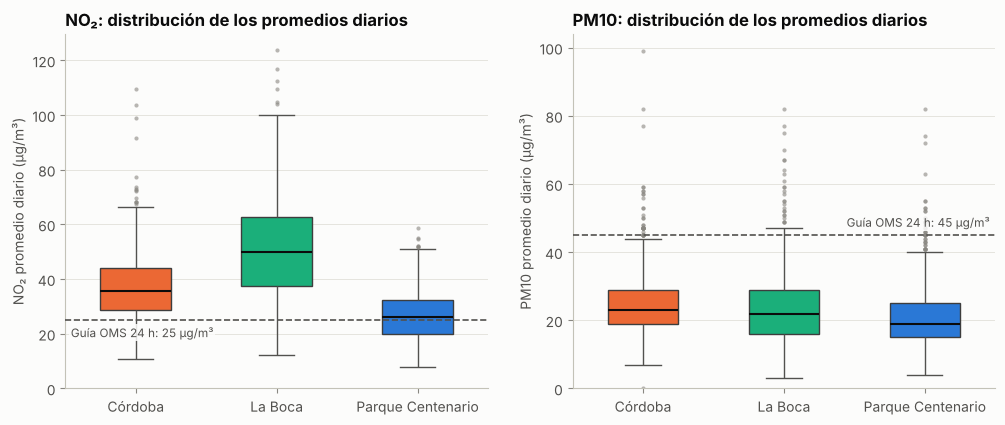

In [16]:
# seaborn trabaja directo sobre el DataFrame: x = categoría, y = valor, hue = color por categoría
diario["estacion"] = diario["id_estacion"].map(NOMBRE)
ORDEN_NOMBRES = [NOMBRE[e] for e in ORDEN_ESTACIONES]
PALETA = {NOMBRE[e]: COLOR_ESTACION[e] for e in ORDEN_ESTACIONES}

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, cont, titulo in [(ejes[0], "no2", "NO₂"), (ejes[1], "pm10", "PM10")]:
    sns.boxplot(data=diario[diario.id_contaminante == cont], x="estacion", y="valor", hue="estacion",
                order=ORDEN_NOMBRES, palette=PALETA, width=0.5, saturation=1, ax=ax,
                medianprops=dict(color=TINTA, linewidth=1.5), whiskerprops=dict(color=TINTA_2),
                capprops=dict(color=TINTA_2),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=TENUE, markeredgecolor="none", alpha=0.6))
    ax.set_xlabel("")
    linea_guia(ax, GUIA[(cont, "24h")], f"Guía OMS 24 h: {GUIA[(cont, '24h')]:.0f} µg/m³",
               lado="izquierda" if cont == "no2" else "derecha", debajo=cont == "no2")
    ax.set_ylabel(f"{titulo} promedio diario (µg/m³)")
    ax.set_title(f"{titulo}: distribución de los promedios diarios")
    ax.set_ylim(bottom=0)
guardar(fig, "02_distribuciones_boxplot")
plt.show()

Figura guardada: reports/figures/03_histograma_no2.png


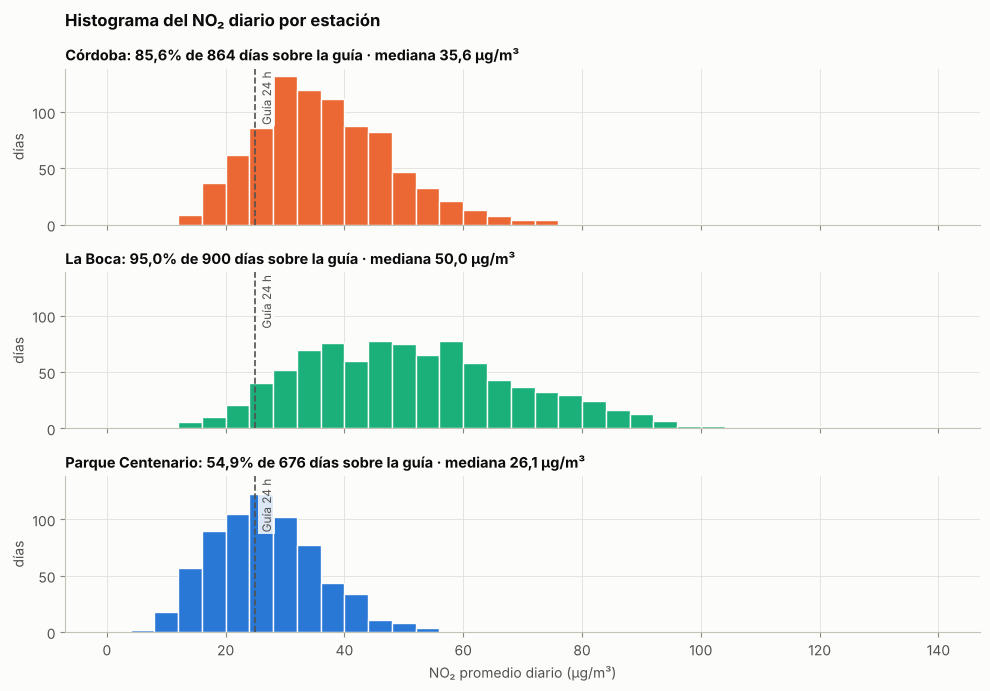

In [17]:
no2 = diario[diario.id_contaminante == "no2"]
fig, ejes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, sharey=True)
bordes = np.arange(0, 141, 4)
for ax, e in zip(ejes, ORDEN_ESTACIONES):
    v = no2[no2.id_estacion == e]["valor"]
    sns.histplot(x=v, bins=bordes, color=COLOR_ESTACION[e], edgecolor=SUPERFICIE, linewidth=1, alpha=1, ax=ax)
    linea_guia(ax, GUIA_NO2, "Guía 24 h", horizontal=False)
    ax.set_title(f"{NOMBRE[e]}: {coma(100 * (v > GUIA_NO2).mean())}% de {len(v)} días sobre la guía · mediana {coma(v.median())} µg/m³",
                 fontsize=10.5)
    ax.set_ylabel("días")
ejes[-1].set_xlabel("NO₂ promedio diario (µg/m³)")
fig.suptitle("Histograma del NO₂ diario por estación", x=0.07, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
guardar(fig, "03_histograma_no2")
plt.show()

**Qué se concluye:**
- El **NO₂** está casi entero por encima de la guía de 24 h en La Boca y Córdoba, pero casi siempre por debajo del
  objetivo intermedio IT2 (50 µg/m³) en Córdoba y Centenario. En La Boca **la mediana (50 µg/m³) está justo en el
  IT2**: la mitad de los días lo supera. Centenario está repartido a ambos lados de la guía.
- El **PM10** está casi siempre por debajo de 45 µg/m³ (las cajas quedan abajo de la guía); lo que la supera son
  colas de pocos días.
- Las distribuciones son **asimétricas a la derecha** (más días bajos y algunos picos): conviene reportar mediana y
  percentiles, no solo promedios. Los puntos sueltos son los días atípicos de la sección 2.4.

## 4. Serie temporal diaria con la guía OMS

**Qué se busca:** ver la evolución, los huecos y la estacionalidad en el tiempo. Puntos = días; línea = media móvil
de 30 días (se corta donde no hay datos, en lugar de inventar una continuidad).

Figura guardada: reports/figures/04_serie_no2.png


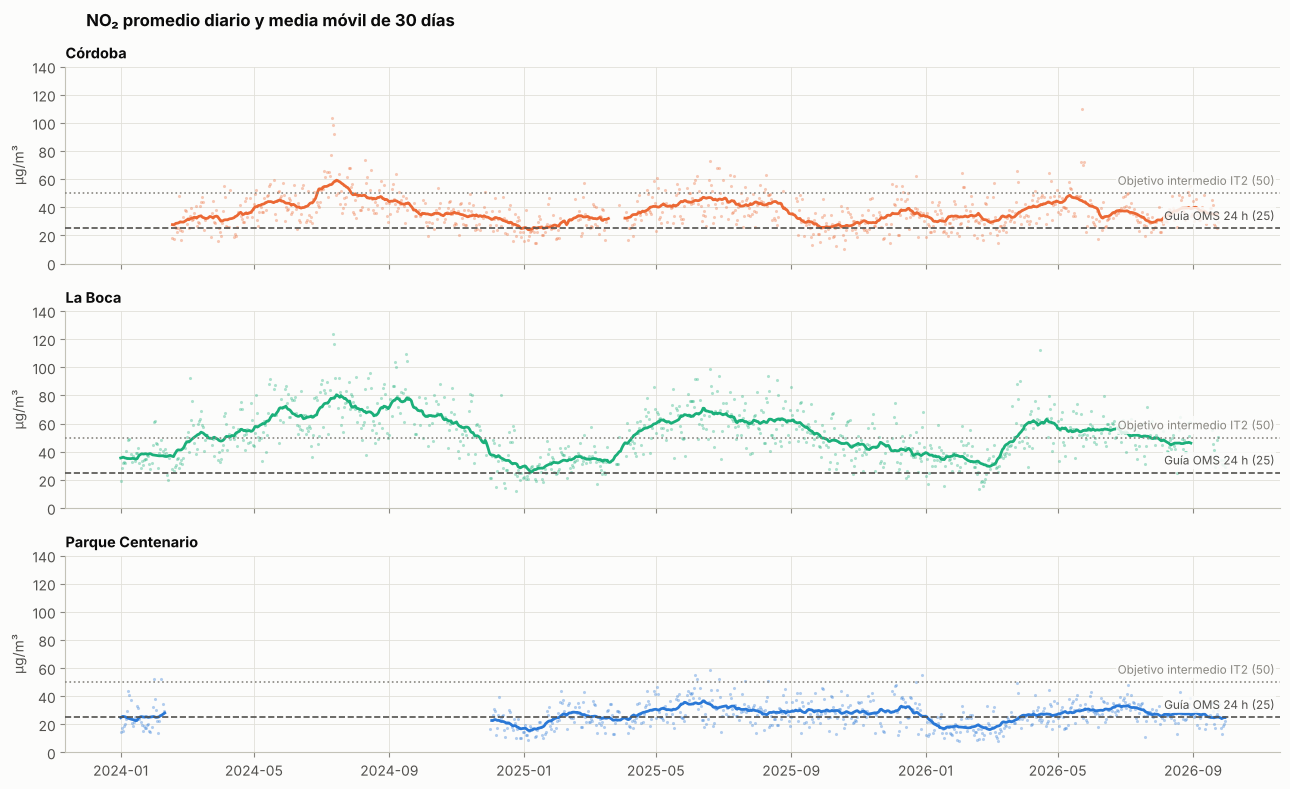

In [18]:
def serie(cont, titulo, guia, extra=None, nombre_fig=None, ymax=None):
    fechas = pd.date_range(dim_calendario.fecha.min(), dim_calendario.fecha.max(), freq="D")
    fig, ejes = plt.subplots(3, 1, figsize=(13, 8), sharex=True, sharey=True)
    for ax, e in zip(ejes, ORDEN_ESTACIONES):
        s = (diario[(diario.id_contaminante == cont) & (diario.id_estacion == e)]
             .set_index(pd.to_datetime(diario.loc[(diario.id_contaminante == cont) & (diario.id_estacion == e), "fecha"]))["valor"]
             .reindex(fechas))
        media = s.rolling(30, min_periods=15, center=True).mean()
        ax.scatter(s.index, s, s=5, color=COLOR_ESTACION[e], alpha=0.35, linewidths=0)
        ax.plot(media.index, media, color=COLOR_ESTACION[e], linewidth=2)
        linea_guia(ax, guia, f"Guía OMS 24 h ({guia:.0f})")
        if extra:
            linea_guia(ax, extra[0], extra[1], estilo=":", color=TENUE)
        ax.set_title(NOMBRE[e], fontsize=10.5)
        ax.set_ylabel("µg/m³")
        if ymax:
            ax.set_ylim(0, ymax)
    fig.suptitle(titulo, x=0.07, ha="left", fontweight="bold", fontsize=12)
    fig.tight_layout()
    guardar(fig, nombre_fig)
    plt.show()

it2_no2 = NIVEL_24H[("no2", "IT2")]
serie("no2", "NO₂ promedio diario y media móvil de 30 días", GUIA_NO2, extra=(it2_no2, f"Objetivo intermedio IT2 ({it2_no2:.0f})"),
      nombre_fig="04_serie_no2", ymax=140)

Figura guardada: reports/figures/05_serie_pm10.png


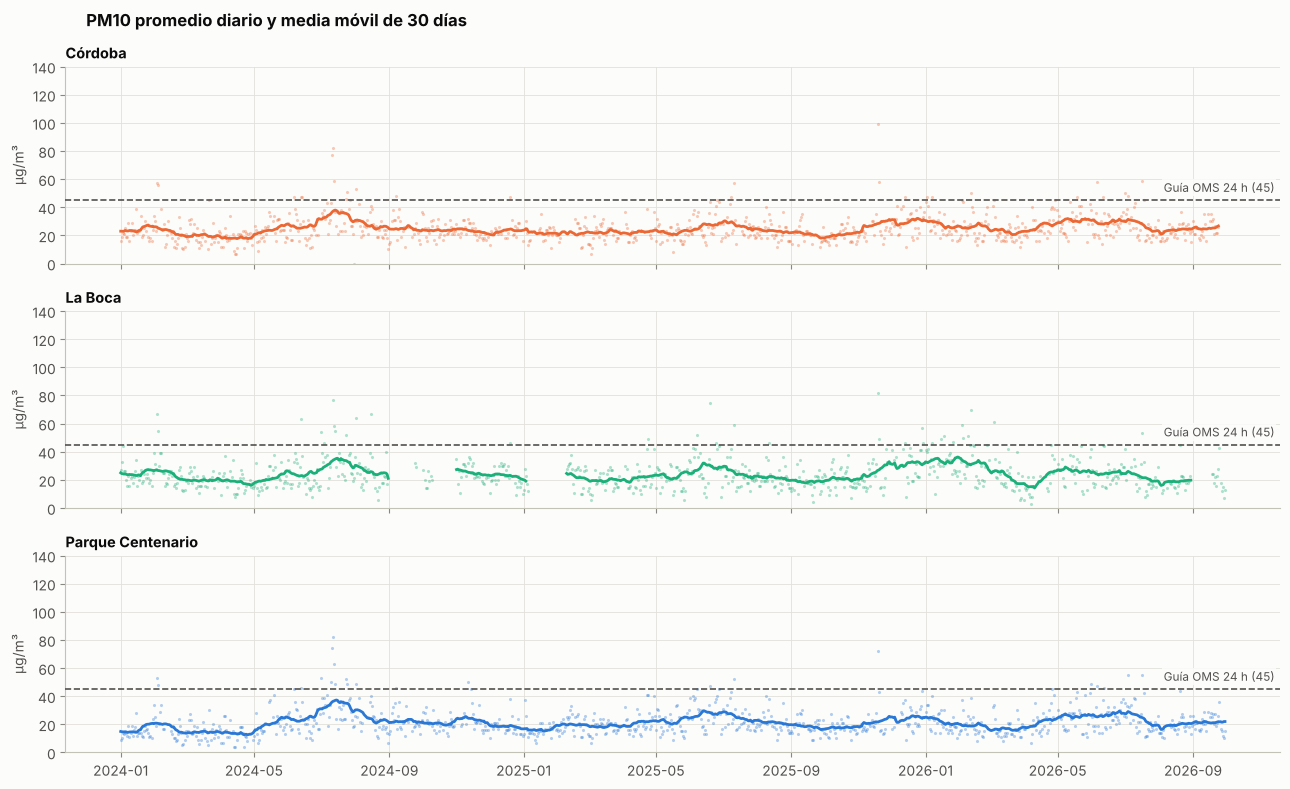

In [19]:
serie("pm10", "PM10 promedio diario y media móvil de 30 días", GUIA_PM10, nombre_fig="05_serie_pm10", ymax=140)

**Qué se concluye:**
- La media móvil de 30 días del NO₂ de **La Boca nunca baja de la guía de 25 µg/m³** en todo el período (su mínimo,
  en enero de 2025, es 25,5) y la de **Córdoba solo baja 8 días**, entre fines de diciembre de 2024 y enero de 2025. La de La Boca pasa
  los meses fríos por encima del objetivo intermedio IT2 (50 µg/m³).
- Hay una **estacionalidad clara**: el NO₂ sube en otoño-invierno y baja en verano, en las tres estaciones.
- El hueco de Centenario (marzo a noviembre de 2024) se ve como un corte en la serie.
- El PM10 vive debajo de la guía y la cruza en picos cortos, varios compartidos por las tres estaciones
  (episodios regionales).

## 5. ¿En qué escalón de la OMS está cada día? (subpreguntas 1 y 2)

Cada día con dato se ubica en el escalón más exigente que cumple: **guía** (AQG), o el objetivo intermedio que
corresponda, o "> IT1" si no cumple ni el menos exigente. Denominador: **días con dato válido** (un día sin dato no
cuenta como día "limpio").

In [20]:
ORDEN_NIVEL = ["AQG", "IT4", "IT3", "IT2", "IT1", "> IT1"]
niveles_dia = (diario[diario.id_contaminante.isin(["no2", "pm10"])]
               .groupby(["id_contaminante", "id_estacion"])["nivel_oms"]
               .value_counts(normalize=True).mul(100).unstack(fill_value=0)
               .reindex(columns=ORDEN_NIVEL, fill_value=0).round(1))
niveles_dia

nivel_oms                     AQG  IT4  IT3   IT2   IT1  > IT1
id_contaminante id_estacion                                   
no2             centenario   45.1  0.0  0.0  53.4   1.5    0.0
                cordoba      14.4  0.0  0.0  73.3  12.4    0.0
                la_boca       5.0  0.0  0.0  45.0  49.9    0.1
pm10            centenario   97.6  1.3  1.0   0.1   0.0    0.0
                cordoba      96.8  1.7  1.1   0.3   0.0    0.0
                la_boca      95.9  1.5  2.3   0.2   0.0    0.0

Figura guardada: reports/figures/06_niveles_oms_diarios.png


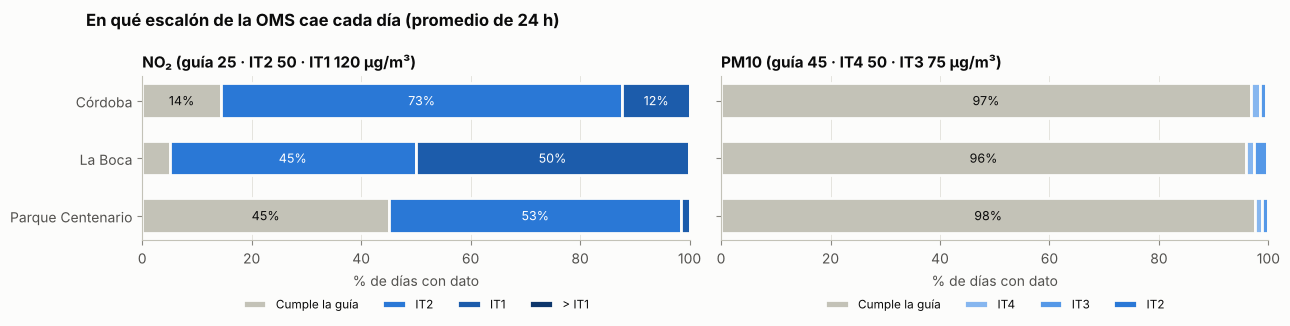

In [21]:
# Barras 100% apiladas: qué parte de los días cae en cada escalón (más oscuro = más lejos de la guía)
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
etiquetas_nivel = {"AQG": "Cumple la guía", "IT4": "IT4", "IT3": "IT3", "IT2": "IT2", "IT1": "IT1", "> IT1": "> IT1"}
for ax, cont, titulo in [(ejes[0], "no2", f"NO₂ (guía {GUIA_NO2:.0f} · IT2 {NIVEL_24H[('no2', 'IT2')]:.0f} · IT1 {NIVEL_24H[('no2', 'IT1')]:.0f} µg/m³)"),
                         (ejes[1], "pm10", f"PM10 (guía {GUIA_PM10:.0f} · IT4 {NIVEL_24H[('pm10', 'IT4')]:.0f} · IT3 {NIVEL_24H[('pm10', 'IT3')]:.0f} µg/m³)")]:
    izquierda = np.zeros(3)
    for nivel in ORDEN_NIVEL:
        valores = np.array([niveles_dia.loc[(cont, e), nivel] for e in ORDEN_ESTACIONES])
        if valores.sum() == 0:
            continue
        ax.barh(ORDEN_NOMBRES, valores, left=izquierda, height=0.6, color=COLOR_NIVEL[nivel],
                edgecolor=SUPERFICIE, linewidth=2, label=etiquetas_nivel[nivel])
        for y, (v, x0) in enumerate(zip(valores, izquierda)):
            if v >= 6:
                ax.text(x0 + v / 2, y, f"{coma(v, 0)}%", ha="center", va="center", fontsize=9,
                        color=TINTA if nivel == "AQG" else "#ffffff")
        izquierda += valores
    ax.set_xlim(0, 100)
    ax.set_xlabel("% de días con dato")
    ax.set_title(titulo, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=5, fontsize=8.5)
ejes[0].invert_yaxis()
fig.suptitle("En qué escalón de la OMS cae cada día (promedio de 24 h)", x=0.07, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
guardar(fig, "06_niveles_oms_diarios")
plt.show()

**Qué se concluye:**
- **NO₂:** ninguna estación cumple la guía diaria la mayoría de los días, pero el **objetivo intermedio IT2
  (50 µg/m³) se cumple el 98,5% de los días en Parque Centenario y el 87,6% en Córdoba**. En **La Boca, solo el
  50,0%**: la mitad de los días supera incluso el IT2. El IT1 (120 µg/m³) se cumple prácticamente siempre (un solo
  día lo supera: La Boca, 124 µg/m³ el 12/07/2024).
- **PM10:** cumple la guía diaria entre el 95,9% y el 97,6% de los días.

### 5.1 Matriz de escalones por estación y año

Lo mismo, año por año y **acumulado**: qué % de días cumple la guía y cada objetivo intermedio (un día que cumple la
guía cumple también todos los IT). Sale de las columnas `pct_cumple_*_24h` de `agg_anual`. Los períodos con menos de 75% de
días con dato quedan vacíos ("—"). 2026 es parcial (enero a septiembre).

Figura guardada: reports/figures/06b_matriz_niveles_no2.png


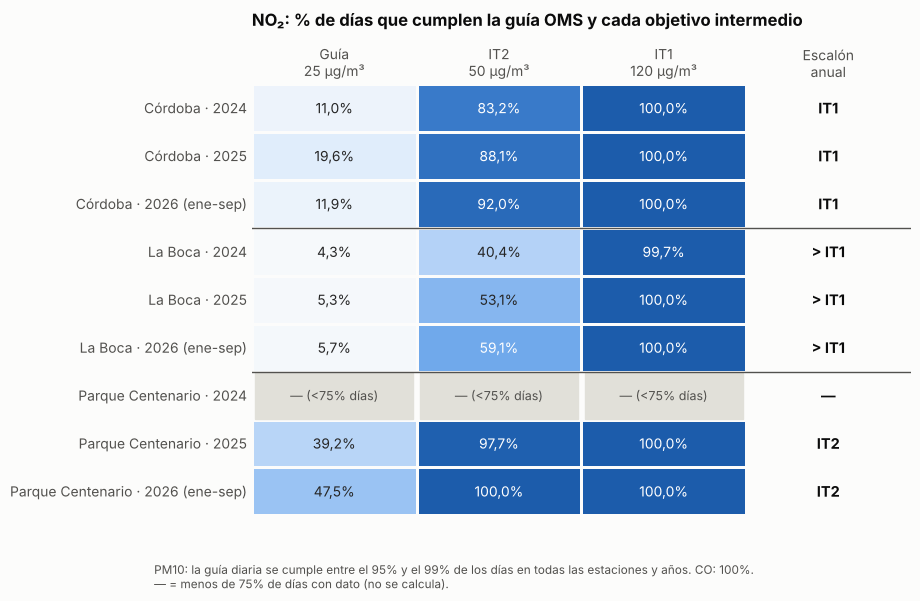

In [22]:
# Columna de agg_anual con el % de días que cumple cada escalón de 24 h (vacía si el período no llega al 75%)
COL_NIVEL = {"AQG": "pct_cumple_guia_24h", "IT4": "pct_cumple_it4_24h", "IT3": "pct_cumple_it3_24h",
             "IT2": "pct_cumple_it2_24h", "IT1": "pct_cumple_it1_24h"}
anual_idx = anual.set_index(["id_estacion", "id_contaminante", "id_periodo"])
periodos_m = [("2024", "2024"), ("2025", "2025"), ("2026", "2026 (ene-sep)")]
niveles_no2 = [(n, f"{'Guía' if n == 'AQG' else n}\n{NIVEL_24H[('no2', n)]:.0f} µg/m³") for n in ("AQG", "IT2", "IT1")]

filas, etiquetas_filas, escalon = [], [], []
for e in ORDEN_ESTACIONES:
    for id_p, txt in periodos_m:
        fila = anual_idx.loc[(e, "no2", id_p)]
        filas.append([100 * fila[COL_NIVEL[n]] for n, _ in niveles_no2])
        etiquetas_filas.append(f"{NOMBRE[e]} · {txt}")
        escalon.append(fila.nivel_oms if pd.notna(fila.nivel_oms) else "—")
tabla_m = pd.DataFrame(filas, index=etiquetas_filas, columns=[t for _, t in niveles_no2])

fig, ax = plt.subplots(figsize=(8.5, 5.6))
textos = tabla_m.map(lambda v: "—" if pd.isna(v) else f"{coma(v)}%")
cmap_m = LinearSegmentedColormap.from_list("cumple", ["#fcfcfb", "#cde2fb", "#5598e7", "#1c5cab"])
sns.heatmap(tabla_m, annot=textos, fmt="", cmap=cmap_m, vmin=0, vmax=100, linewidths=2, linecolor=SUPERFICIE,
            cbar=False, annot_kws={"fontsize": 10}, ax=ax)  # sin barra de color: los % van escritos
ax.grid(False)
for i, fila in enumerate(tabla_m.values):  # períodos sin datos suficientes: gris con texto
    for j, v in enumerate(fila):
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((j + 0.02, i + 0.02), 0.96, 0.96, color=GRILLA, zorder=2))
            ax.text(j + 0.5, i + 0.5, "— (<75% días)", ha="center", va="center", fontsize=9, color=TINTA_2, zorder=3)
for i, txt in enumerate(escalon):  # columna de texto: escalón del promedio anual
    ax.text(3.5, i + 0.5, txt, ha="center", va="center", fontsize=10.5, color=TINTA, fontweight="bold")
ax.text(3.5, -0.08, "Escalón\nanual", ha="center", va="bottom", fontsize=10, color=TINTA_2)
ax.set_xlim(0, 4)
for k in (3, 6):
    ax.axhline(k, color=TINTA_2, linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("")
ax.xaxis.tick_top()
ax.tick_params(axis="both", length=0)
ax.set_title("NO₂: % de días que cumplen la guía OMS y cada objetivo intermedio", pad=42)
fig.text(0.01, -0.02, "PM10: la guía diaria se cumple entre el 95% y el 99% de los días en todas las estaciones y años. "
         "CO: 100%.\n— = menos de 75% de días con dato (no se calcula).", fontsize=8.5, color=TINTA_2)
guardar(fig, "06b_matriz_niveles_no2")
plt.show()

In [23]:
# PM10 y CO: la misma matriz en tabla (casi todo cerca de 100%, por eso no va al gráfico)
(anual[anual.id_contaminante.isin(["pm10", "co"]) & (anual.id_periodo != "movil_12m")]
 .set_index(["id_contaminante", "id_estacion", "id_periodo"])[list(COL_NIVEL.values())]
 .rename(columns={col: nivel for nivel, col in COL_NIVEL.items()})
 .mul(100).round(1)
 .sort_index()
 .dropna(axis=1, how="all"))   # sin columna para los escalones que la OMS no define

AQG   IT4    IT3    IT2    IT1
id_contaminante id_estacion id_periodo                                  
co              centenario  2024        100.0   NaN    NaN    NaN  100.0
                            2025        100.0   NaN    NaN    NaN  100.0
                            2026        100.0   NaN    NaN    NaN  100.0
                cordoba     2024          NaN   NaN    NaN    NaN    NaN
                            2025        100.0   NaN    NaN    NaN  100.0
                            2026        100.0   NaN    NaN    NaN  100.0
                la_boca     2024        100.0   NaN    NaN    NaN  100.0
                            2025        100.0   NaN    NaN    NaN  100.0
                            2026        100.0   NaN    NaN    NaN  100.0
pm10            centenario  2024         95.6  98.1   99.7  100.0  100.0
                            2025         99.1  99.4  100.0  100.0  100.0
                            2026         98.0  99.2  100.0  100.0  100.0
                cordoba     2024         96.1  97.9   99.4  100.0  100.0
                            2025         98.3  99.0   99.7  100.0  100.0
                            2026         96.0  98.8  100.0  100.0  100.0
                la_boca     2024         95.9  96.6   99.7  100.0  100.0
                            2025         96.4  98.3   99.7  100.0  100.0
                            2026         95.4  97.2  100.0  100.0  100.0

**Qué se concluye:**
- **Centenario y Córdoba cumplen el IT2 diario casi todos los días en todos los años** (83% a 100%) y el IT1 siempre;
  su promedio anual se mantiene en el mismo escalón los tres años (IT2 y IT1).
- **La Boca mejora año a año en el IT2 diario: 40% → 53% → 59% de los días** (2024 → 2025 → 2026 parcial), aunque su
  promedio anual sigue por encima del IT1. Sin datos meteorológicos no se puede atribuir a una mejora real de las
  emisiones (un año más ventoso o lluvioso también baja el NO₂), y a septiembre de 2026 le falta más de la mitad de
  los días.
- La guía diaria se cumple poco: entre 4% y 48% de los días según estación y año.

### 5.2 % de días por encima de la guía diaria

El mismo dato, resumido en "días que superan la guía": es la forma más directa de comunicarlo, pero conviene leerlo
junto con los escalones.

In [24]:
pct = (diario.groupby(["id_contaminante", "id_estacion"])
       .agg(dias_con_dato=("valor", "size"), dias_sobre_guia=("supera_guia", "sum"), pct=("supera_guia", "mean")))
pct["pct"] = (100 * pct["pct"]).round(1)
pct

dias_con_dato dias_sobre_guia   pct
id_contaminante id_estacion                                     
co              centenario             874               0   0.0
                cordoba                817               0   0.0
                la_boca                871               0   0.0
no2             centenario             676             371  54.9
                cordoba                864             740  85.6
                la_boca                900             855  95.0
pm10            centenario             913              22   2.4
                cordoba                888              28   3.2
                la_boca                812              33   4.1

Figura guardada: reports/figures/07_pct_dias_sobre_guia.png


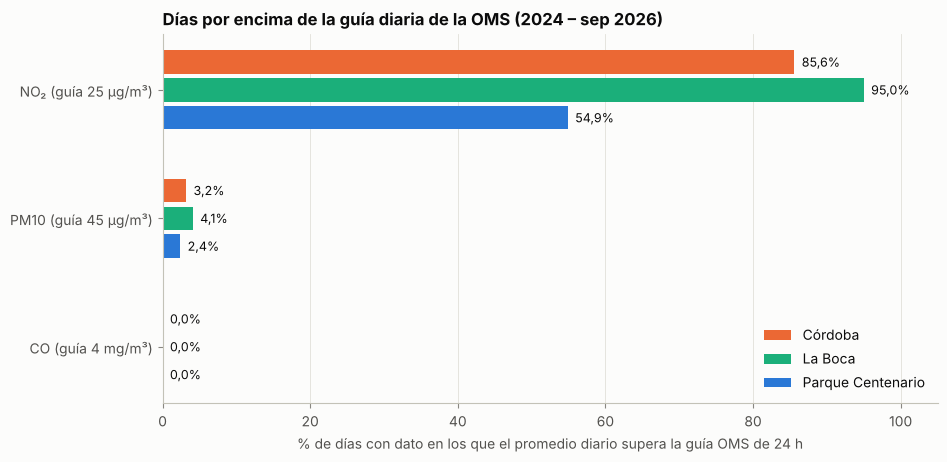

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.8))
contaminantes = [("no2", f"NO₂ (guía {GUIA_NO2:.0f} µg/m³)"), ("pm10", f"PM10 (guía {GUIA_PM10:.0f} µg/m³)"),
                 ("co", f"CO (guía {GUIA_CO:.0f} mg/m³)")]
alto, sep = 0.26, 1.2
for i, (cont, etiqueta) in enumerate(contaminantes):
    for j, e in enumerate(ORDEN_ESTACIONES):
        y = i * sep + (j - 1) * alto
        v = pct.loc[(cont, e), "pct"]
        ax.barh(y, v, height=alto - 0.04, color=COLOR_ESTACION[e], label=NOMBRE[e] if i == 0 else None)
        ax.text(v + 1, y, f"{coma(v)}%", va="center", fontsize=9, color=TINTA)
ax.set_yticks([i * sep for i in range(3)], [c[1] for c in contaminantes])
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_xlabel("% de días con dato en los que el promedio diario supera la guía OMS de 24 h")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title("Días por encima de la guía diaria de la OMS (2024 – sep 2026)")
guardar(fig, "07_pct_dias_sobre_guia")
plt.show()

In [26]:
# La definición formal de la OMS: el percentil 99 anual de los valores diarios contra la guía de 24 h
p99 = anual[anual.tipo_periodo != "movil_12m"].pivot_table(
    index=["id_contaminante", "id_estacion"], columns="id_periodo", values="p99_veces_guia_24h")
print("Percentil 99 anual / guía de 24 h (más de 1 = no se cumple la guía en sentido formal):")
p99.loc[["no2", "pm10", "co"]]

Percentil 99 anual / guía de 24 h (más de 1 = no se cumple la guía en sentido formal):


id_periodo                   2024  2025  2026
id_contaminante id_estacion                  
no2             centenario    NaN  2.08  1.74
                cordoba      3.15  2.53  2.83
                la_boca      4.18  3.67  3.43
pm10            centenario   1.18  1.00  1.07
                cordoba      1.26  1.04  1.14
                la_boca      1.43  1.27  1.29
co              centenario   0.27  0.32  0.27
                cordoba       NaN  0.37  0.38
                la_boca      0.29  0.17  0.24

**Qué se concluye (subpreguntas 1 y 3):**
- **NO₂:** La Boca supera la guía diaria el **95,0%** de los días, Córdoba el **85,6%** y Parque Centenario el
  **54,9%** (pero, como se vio arriba, Centenario y Córdoba casi siempre cumplen el IT2). Con el criterio formal
  (P99 anual), el NO₂ de La Boca está entre **3,4 y 4,2 veces** la guía.
- **PM10:** entre 2,4% y 4,1% de los días. **Pero el P99 anual llega a 45 µg/m³ o más en todas las estaciones y
  años** (1,00 a 1,43 veces): con la definición formal, el PM10 tampoco cumple la guía de 24 h (Centenario 2025 queda
  justo en el límite).
- **CO:** nunca se acerca a la guía (el P99 es menos de 0,4 veces los 4 mg/m³). No es un problema en la Ciudad.
- Nota: el denominador son los **días con dato**. Dividir por todos los días (contar un día sin dato como "limpio")
  subestimaría el problema, sobre todo en Centenario: daría 37% en lugar de 55%.
- **Para las hipótesis:** el NO₂ es, por lejos, el contaminante que más se aleja de la guía (H1). Entre estaciones, la
  más comprometida es **La Boca** y no Córdoba, la de tránsito intenso (H2).

In [27]:
# Racha más larga de cada año: días con dato seguidos por encima de la guía de 24 h
# (técnica gaps and islands, calculada en gold.agg_anual)
(anual[(anual.racha_maxima_dias > 0) & (anual.id_periodo != "movil_12m")]
 [["id_contaminante", "id_estacion", "periodo", "racha_maxima_dias", "racha_desde", "racha_hasta"]]
 .sort_values(["id_contaminante", "racha_maxima_dias"], ascending=[True, False]))

,id_contaminante,id_estacion,periodo,racha_maxima_dias,racha_desde,racha_hasta
140,no2,la_boca,2024,254,2024-02-14,2024-11-28
141,no2,la_boca,2025,206,2025-03-17,2025-10-26
142,no2,la_boca,2026 (parcial: 01/01 a 30/09),148,2026-02-26,2026-08-16
87,no2,cordoba,2025,111,2025-05-02,2025-09-06
86,no2,cordoba,2024,108,2024-06-10,2024-10-05
88,no2,cordoba,2026 (parcial: 01/01 a 30/09),72,2026-03-16,2026-05-26
34,no2,centenario,2026 (parcial: 01/01 a 30/09),26,2026-06-15,2026-07-10
33,no2,centenario,2025,15,2025-05-28,2025-06-11
32,no2,centenario,2024,4,2024-01-07,2024-01-10
50,pm10,centenario,2024,5,2024-07-10,2024-07-14


La racha más larga de NO₂: **La Boca, 254 días con dato seguidos sobre la guía** (14/02/2024 a 28/11/2024: 289 días
de calendario, 35 sin dato en el medio), y en 2025 repite con 206 (17/03 a 26/10). Córdoba llega a 111 (mayo a
septiembre de 2025) y Centenario a 26. Una racha se corta con un día con dato que cumple la guía o con un hueco de
más de 7 días sin dato. Los huecos cortos (casi siempre días que la fuente trae cortados al mediodía) no la cortan
ni la alargan.

## 6. Promedio anual contra la guía anual y los objetivos intermedios (subpregunta 2)

Solo períodos con al menos 75% de días con dato. **2026 es parcial** (enero a septiembre, sin primavera ni verano):
para compararlo con un año completo se usan los **últimos 12 meses** (octubre 2025 a septiembre 2026).

In [28]:
cols = ["id_estacion", "periodo", "completitud", "promedio_anual", "guia_anual", "veces_guia_anual",
        "nivel_oms", "proximo_nivel", "ug_para_proximo_nivel"]
anual[anual.id_contaminante == "no2"][cols].sort_values(["id_estacion", "periodo"])

,id_estacion,periodo,completitud,promedio_anual,guia_anual,veces_guia_anual,nivel_oms,proximo_nivel,ug_para_proximo_nivel
32,centenario,2024,0.1885,NaN,10.0,NaN,NaN,NaN,NaN
33,centenario,2025,0.9370,28.56,10.0,2.86,IT2,IT3,8.56
34,centenario,2026 (parcial: 01/01 a 30/09),0.9707,25.29,10.0,2.53,IT2,IT3,5.29
35,centenario,Últimos 12 meses (10/2025 a 09/2026),0.9507,26.32,10.0,2.63,IT2,IT3,6.32
86,cordoba,2024,0.7951,39.29,10.0,3.93,IT1,IT2,9.29
87,cordoba,2025,0.8548,35.30,10.0,3.53,IT1,IT2,5.30
88,cordoba,2026 (parcial: 01/01 a 30/09),0.9560,36.35,10.0,3.64,IT1,IT2,6.35
89,cordoba,Últimos 12 meses (10/2025 a 09/2026),0.9507,35.13,10.0,3.51,IT1,IT2,5.13
140,la_boca,2024,0.8989,56.55,10.0,5.65,> IT1,IT1,16.55
141,la_boca,2025,0.9342,49.97,10.0,5.00,> IT1,IT1,9.97


In [29]:
anual[anual.id_contaminante == "pm10"][cols].sort_values(["id_estacion", "periodo"])

,id_estacion,periodo,completitud,promedio_anual,guia_anual,veces_guia_anual,nivel_oms,proximo_nivel,ug_para_proximo_nivel
50,centenario,2024,0.8770,21.03,15.0,1.40,IT3,IT4,1.03
51,centenario,2025,0.9260,21.14,15.0,1.41,IT3,IT4,1.14
52,centenario,2026 (parcial: 01/01 a 30/09),0.9304,22.01,15.0,1.47,IT3,IT4,2.01
53,centenario,Últimos 12 meses (10/2025 a 09/2026),0.9096,21.71,15.0,1.45,IT3,IT4,1.71
104,cordoba,2024,0.9098,24.47,15.0,1.63,IT3,IT4,4.47
105,cordoba,2025,0.8274,23.86,15.0,1.59,IT3,IT4,3.86
106,cordoba,2026 (parcial: 01/01 a 30/09),0.9267,26.70,15.0,1.78,IT3,IT4,6.70
107,cordoba,Últimos 12 meses (10/2025 a 09/2026),0.9178,26.40,15.0,1.76,IT3,IT4,6.40
158,la_boca,2024,0.7978,23.88,15.0,1.59,IT3,IT4,3.88
159,la_boca,2025,0.8274,23.22,15.0,1.55,IT3,IT4,3.22


Figura guardada: reports/figures/08_promedio_anual_vs_oms.png


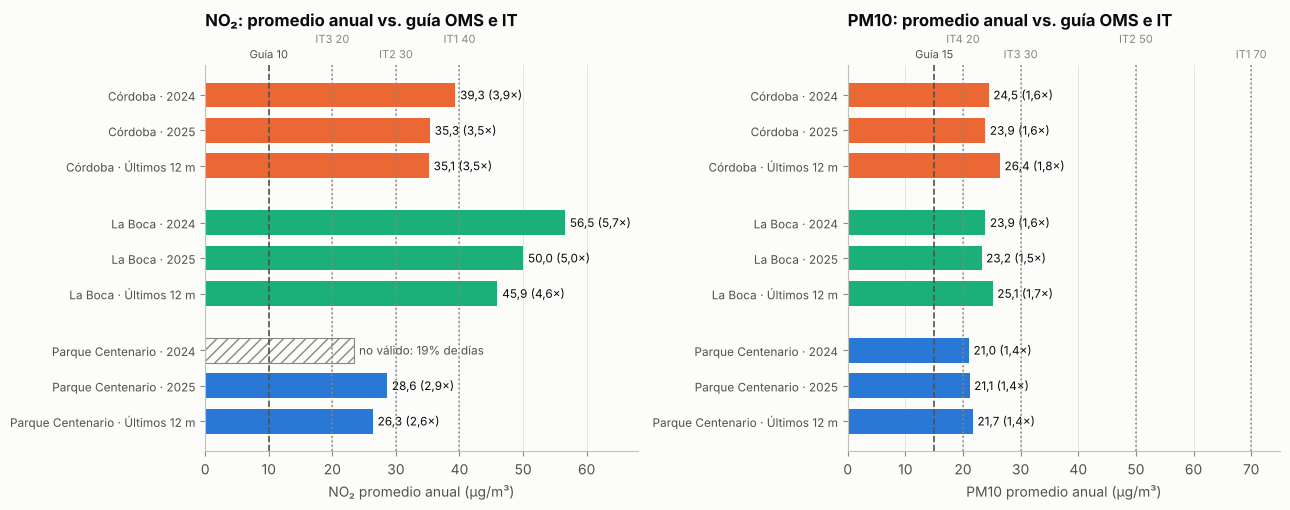

In [30]:
periodos = [("2024", "2024"), ("2025", "2025"), ("movil_12m", "Últimos 12 m")]
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, cont, titulo in [(ejes[0], "no2", "NO₂"), (ejes[1], "pm10", "PM10")]:
    etiquetas, y = [], 0
    for e in ORDEN_ESTACIONES:
        for id_p, txt in periodos:
            fila = anual[(anual.id_contaminante == cont) & (anual.id_estacion == e) & (anual.id_periodo == id_p)].iloc[0]
            if fila.es_valido:
                ax.barh(y, fila.promedio_anual, height=0.7, color=COLOR_ESTACION[e])
                ax.text(fila.promedio_anual + 0.8, y, f"{coma(fila.promedio_anual)} ({coma(fila.promedio_anual / fila.guia_anual)}×)",
                        va="center", fontsize=8.5, color=TINTA)
            else:
                ax.barh(y, fila.promedio_referencial, height=0.7, color="none", edgecolor=TENUE, hatch="///", linewidth=0.8)
                ax.text(fila.promedio_referencial + 0.8, y, f"no válido: {coma(100 * fila.completitud, 0)}% de días",
                        va="center", fontsize=8.5, color=TINTA_2)
            etiquetas.append((y, f"{NOMBRE[e]} · {txt}"))
            y += 1
        y += 0.6
    ax.set_yticks([p for p, _ in etiquetas], [t for _, t in etiquetas], fontsize=8.5)
    ax.invert_yaxis()
    for k, r in enumerate(guia_oms[(guia_oms.id_contaminante == cont) & (guia_oms.promedio == "anual")]
                          .sort_values("umbral").itertuples()):
        estilo = "--" if r.nivel == "AQG" else ":"
        color = TINTA_2 if r.nivel == "AQG" else TENUE
        ax.axvline(r.umbral, color=color, linestyle=estilo, linewidth=1.2, zorder=3)
        ax.annotate(f"{'Guía' if r.nivel == 'AQG' else r.nivel} {r.umbral:.0f}", xy=(r.umbral, 1.0),
                    xycoords=("data", "axes fraction"), xytext=(0, 3 + 11 * (k % 2)), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color=color)
    ax.set_xlabel(f"{titulo} promedio anual (µg/m³)")
    ax.set_title(f"{titulo}: promedio anual vs. guía OMS e IT", pad=28)
    ax.grid(axis="y", visible=False)
ejes[0].set_xlim(0, 68)
ejes[1].set_xlim(0, 75)
fig.tight_layout()
guardar(fig, "08_promedio_anual_vs_oms")
plt.show()

**Qué se concluye (subpregunta 2):**
- **NO₂, últimos 12 meses:** ninguna estación cumple la guía anual de 10 µg/m³, pero dos están en escalones
  intermedios: **Parque Centenario cumple el IT2** (26,3 µg/m³, 2,6 veces la guía; le faltan ~6 µg/m³ para el IT3) y
  **Córdoba cumple el IT1** (35,1 µg/m³, 3,5 veces; le faltan ~5 µg/m³ para el IT2). **La Boca no cumple ni el IT1**
  (45,9 µg/m³, 4,6 veces la guía): le faltan ~6 µg/m³ para llegar al primer escalón.
- En 2024, La Boca llegó a **56,5 µg/m³ (5,7 veces)**.
- **PM10:** entre 21,7 y 26,4 µg/m³ en los últimos 12 meses, **1,4 a 1,8 veces** la guía anual de 15 µg/m³: las
  tres estaciones están en el **IT3**. El PM10 casi no supera la guía diaria, pero tampoco cumple la anual.

## 7. Cumplimiento por tipo de día y por estación del año (subpreguntas 4 y 5)

**Qué se busca:** si la brecha depende de la actividad urbana (H3) y de la época del año.

In [31]:
d = diario.merge(dim_calendario[["fecha", "tipo_dia_etiqueta", "orden_tipo_dia", "estacion_del_anio",
                                 "orden_estacion_del_anio", "nombre_dia", "dia_semana", "mes"]], on="fecha")
no2d = d[d.id_contaminante == "no2"]
tipo = (no2d.groupby(["id_estacion", "orden_tipo_dia", "tipo_dia_etiqueta"])
        .agg(dias=("valor", "size"), no2_promedio=("valor", "mean"), pct_sobre_guia=("supera_guia", "mean"))
        .reset_index())
tipo["variacion_vs_habil_pct"] = 100 * (tipo.no2_promedio / tipo.groupby("id_estacion").no2_promedio.transform("first") - 1)
tipo["pct_sobre_guia"] *= 100
tipo.round(1)

,id_estacion,orden_tipo_dia,tipo_dia_etiqueta,dias,no2_promedio,pct_sobre_guia,variacion_vs_habil_pct
0,centenario,1,Hábil,449,28.7,64.142539,0.0
1,centenario,2,Sábado,97,24.8,44.329897,-13.4
2,centenario,3,Domingo,94,21.1,30.851064,-26.4
3,centenario,4,Feriado,36,22.6,30.555556,-21.0
4,cordoba,1,Hábil,573,38.8,91.273997,0.0
5,cordoba,2,Sábado,122,36.4,81.147541,-6.1
6,cordoba,3,Domingo,121,30.8,70.247934,-20.6
7,cordoba,4,Feriado,48,31.6,68.75,-18.7
8,la_boca,1,Hábil,601,53.8,97.33777,0.0
9,la_boca,2,Sábado,124,49.5,93.548387,-8.0


Figura guardada: reports/figures/09_tipo_dia.png


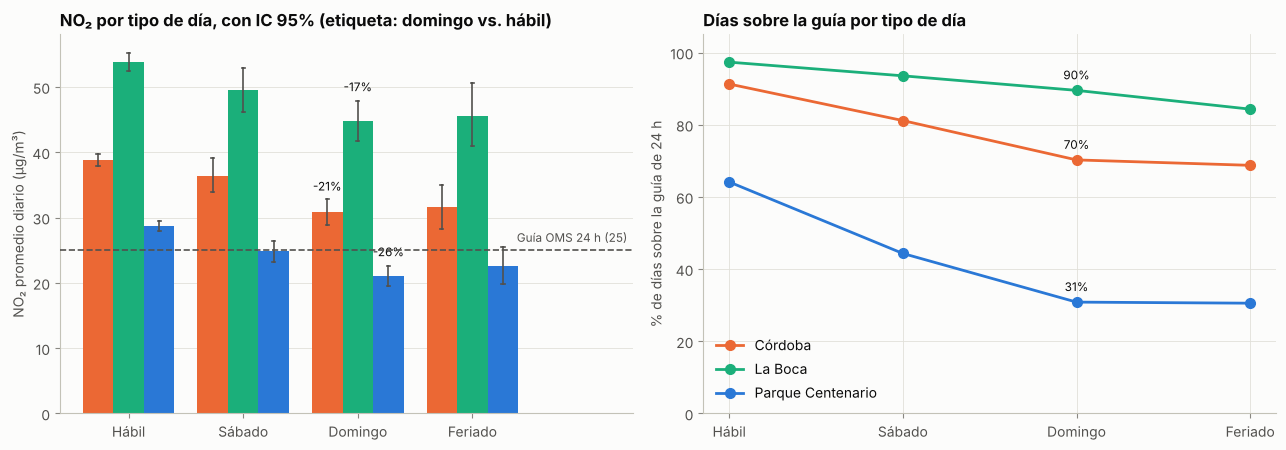

In [32]:
tipos = ["Hábil", "Sábado", "Domingo", "Feriado"]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6))
# seaborn calcula el promedio de cada grupo y su intervalo de confianza del 95% (las rayitas)
sns.barplot(data=no2d, x="tipo_dia_etiqueta", y="valor", hue="estacion", order=tipos, hue_order=ORDEN_NOMBRES,
            palette=PALETA, saturation=1, errorbar=("ci", 95), seed=0, err_kws={"color": TINTA_2, "linewidth": 1.2},
            capsize=0.08, ax=ejes[0], legend=False)
ancho = 0.8 / 3
for j, e in enumerate(ORDEN_ESTACIONES):
    t = tipo[tipo.id_estacion == e].set_index("tipo_dia_etiqueta").loc[tipos]
    domingo = no2d[(no2d.id_estacion == e) & (no2d.tipo_dia_etiqueta == "Domingo")]["valor"]
    techo_ic = domingo.mean() + 1.96 * domingo.std() / np.sqrt(len(domingo))  # aprox. del IC para ubicar la etiqueta
    ejes[0].text(2 + (j - 1) * ancho, techo_ic + 1, f"{coma(t.variacion_vs_habil_pct.iloc[2], 0)}%",
                 ha="center", va="bottom", fontsize=8.5, color=TINTA)
    ejes[1].plot(range(4), t.pct_sobre_guia, marker="o", markersize=7, color=COLOR_ESTACION[e], label=NOMBRE[e])
    ejes[1].annotate(f"{coma(t.pct_sobre_guia.iloc[2], 0)}%", (2, t.pct_sobre_guia.iloc[2]), xytext=(0, 8),
                     textcoords="offset points", ha="center", fontsize=8.5, color=TINTA)
linea_guia(ejes[0], GUIA_NO2, f"Guía OMS 24 h ({GUIA_NO2:.0f})")
ejes[0].set_xlim(-0.6, 4.4)  # espacio a la derecha para la etiqueta de la guía
ejes[0].set_xlabel("")
ejes[0].set_ylabel("NO₂ promedio diario (µg/m³)")
ejes[0].set_title("NO₂ por tipo de día, con IC 95% (etiqueta: domingo vs. hábil)")
ejes[1].legend(loc="lower left")
ejes[0].grid(axis="x", visible=False)
ejes[1].set_xticks(range(4), tipos)
ejes[1].set_ylim(0, 105)
ejes[1].set_ylabel("% de días sobre la guía de 24 h")
ejes[1].set_title("Días sobre la guía por tipo de día")
fig.tight_layout()
guardar(fig, "09_tipo_dia")
plt.show()

**Qué se concluye (subpregunta 4, H3):**
- Con menos actividad el NO₂ baja: el **domingo** está **26% (Centenario), 21% (Córdoba) y 17% (La Boca)** por
  debajo del día hábil; los feriados se parecen a los domingos y los sábados quedan en el medio. Los intervalos de
  confianza del día hábil y del domingo no se superponen: la diferencia no es ruido. Es consistente con que el
  tránsito sea una fuente principal.
- **Pero la brecha no se cierra:** aun los domingos, el NO₂ supera la guía en el **90% de los días en La Boca** y en
  el 70% en Córdoba. H3 se sostiene solo a medias: la reducción es visible, el incumplimiento sigue.
- La Boca es la que menos baja el fin de semana: es consistente con fuentes que no paran los domingos (la APrA la
  describe con "incidencia de fuentes fijas": puerto, polo de Dock Sud, tránsito pesado). Ayuda a entender por qué
  H2 no se sostiene: la peor no es Córdoba, la de tránsito intenso. Con estos datos no se puede atribuir la causa.

Figura guardada: reports/figures/10_estacionalidad.png


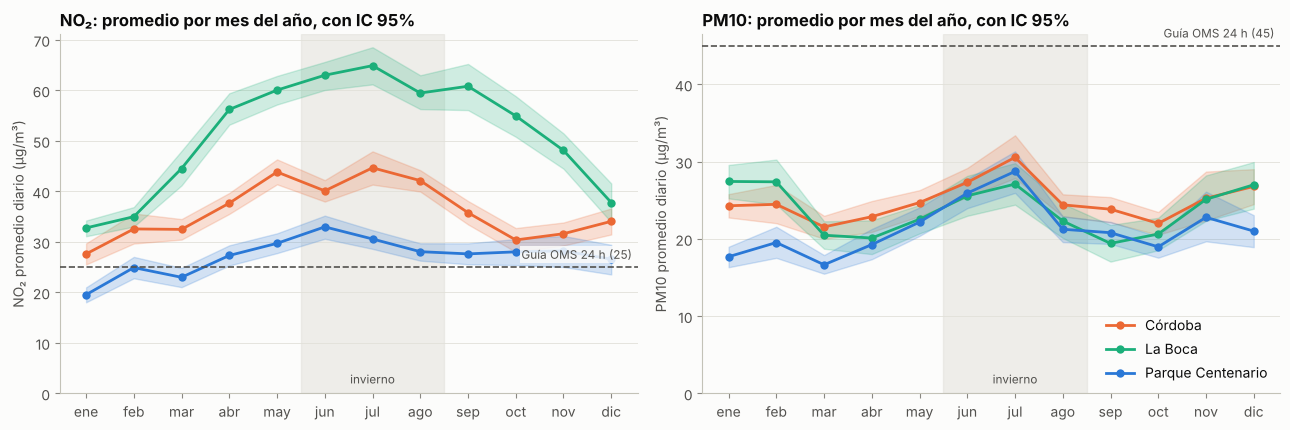

In [33]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, cont, titulo in [(ejes[0], "no2", "NO₂"), (ejes[1], "pm10", "PM10")]:
    ax.axvspan(5.5, 8.5, color=GRILLA, alpha=0.5, zorder=0)
    ax.text(7, 0.02, "invierno", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8.5, color=TINTA_2)
    # seaborn promedia los días de cada mes y sombrea el intervalo de confianza del 95%
    sns.lineplot(data=d[d.id_contaminante == cont], x="mes", y="valor", hue="estacion", hue_order=ORDEN_NOMBRES,
                 palette=PALETA, marker="o", markersize=6, markeredgecolor="none", errorbar=("ci", 95), seed=0, ax=ax)
    linea_guia(ax, GUIA[(cont, "24h")], f"Guía OMS 24 h ({GUIA[(cont, '24h')]:.0f})")
    ax.set_xticks(range(1, 13), MES)
    ax.set_xlabel("")
    ax.set_ylim(0, None)
    ax.set_ylabel(f"{titulo} promedio diario (µg/m³)")
    ax.set_title(f"{titulo}: promedio por mes del año, con IC 95%")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower right", title=None)
ejes[0].get_legend().remove()
fig.tight_layout()
guardar(fig, "10_estacionalidad")
plt.show()

In [34]:
(d[d.id_contaminante.isin(["no2", "pm10"])]
 .groupby(["id_contaminante", "id_estacion", "orden_estacion_del_anio", "estacion_del_anio"])
 .agg(dias=("valor", "size"), promedio=("valor", "mean"), pct_sobre_guia=("supera_guia", "mean"))
 .assign(pct_sobre_guia=lambda x: 100 * x.pct_sobre_guia).round(1)
 .droplevel("orden_estacion_del_anio"))

dias  promedio pct_sobre_guia
id_contaminante id_estacion estacion_del_anio                               
no2             centenario  verano              213      23.1      35.211268
                            otoño               173      26.6      51.445087
                            invierno            180      30.5      76.111111
                            primavera           110      27.9      63.636364
                cordoba     verano              177      31.4      68.361582
                            otoño               249      38.3      91.164659
                            invierno            258      42.3      96.511628
                            primavera           180      32.9      79.444444
                la_boca     verano              237      34.8      83.122363
                            otoño               239      53.8       98.74477
                            invierno            256      62.4      99.609375
                            primavera           168      55.2      99.404762
pm10            centenario  verano              216      19.1       0.925926
                            otoño               249      19.4       0.401606
                            invierno            265      25.4       6.037736
                            primavera           183      20.7       1.639344
                cordoba     verano              202      25.0       3.465347
                            otoño               241      23.0       0.414938
                            invierno            266      27.3       6.390977
                            primavera           179      23.7       1.675978
                la_boca     verano              193      27.3       7.253886
                            otoño               235      21.1       0.851064
                            invierno            250      25.0            6.0
                            primavera           134      22.0       1.492537

**Qué se concluye (subpregunta 5):**
- **Estacionalidad fuerte en el NO₂:** en invierno el promedio es **1,8 veces** el de verano en La Boca
  (62,4 contra 34,8 µg/m³) y ~1,3 veces en Córdoba y Centenario. En invierno La Boca supera la guía el 99,6% de los
  días y Córdoba el 96,5%. Es consistente con la menor dispersión atmosférica en los meses fríos (inversiones
  térmicas) y con más calefacción; sin datos meteorológicos no se puede separar cada efecto.
- El **PM10** varía poco con la época del año: sube algo en invierno, pero se mantiene debajo de la guía de 24 h.

## 8. Ritmo semanal y perfil horario

**Qué se busca:** el patrón de lunes a domingo (promedio de 24 h) y, con los datos horarios del NO₂, **en qué horas
del día** aparece la diferencia entre un día hábil y un domingo (H3).

Figura guardada: reports/figures/11_ritmo_semanal.png


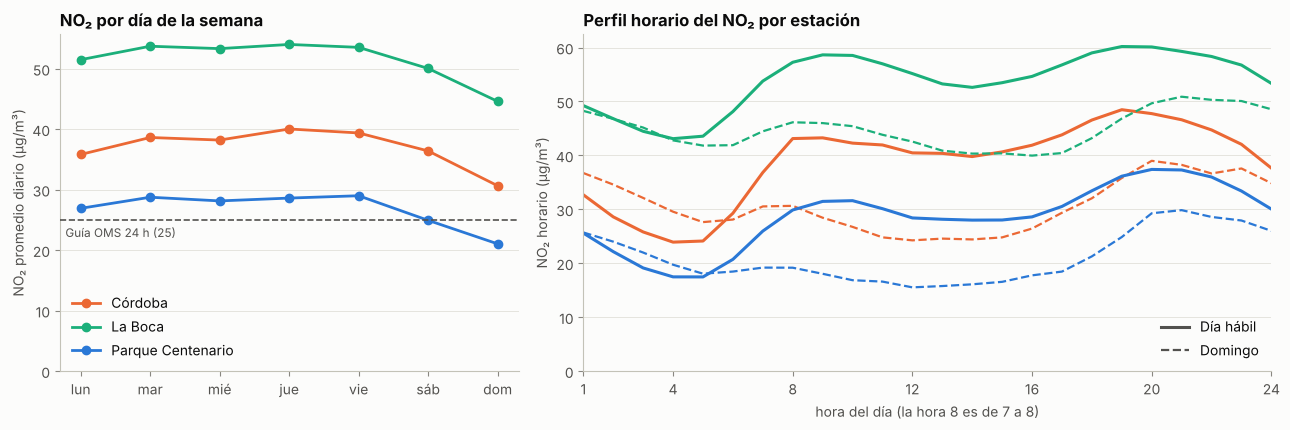

In [35]:
from matplotlib.lines import Line2D

semana = (diario[diario.id_contaminante == "no2"]
          .merge(dim_calendario[["fecha", "dia_semana"]], on="fecha")
          .groupby(["id_estacion", "dia_semana"])["valor"].mean().reset_index())
# Perfil horario: promedio de cada hora del día, hábil contra domingo (segunda tabla de hechos)
perfil = (horaria[horaria.es_valido]
          .merge(dim_calendario[["fecha", "tipo_dia"]], on="fecha")
          .query("tipo_dia in ['habil', 'domingo']")
          .groupby(["id_estacion", "tipo_dia", "hora"])["valor_masa"].mean().reset_index())
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.5]})
for e in ORDEN_ESTACIONES:
    s = semana[semana.id_estacion == e]
    ejes[0].plot(s.dia_semana, s.valor, marker="o", markersize=6, color=COLOR_ESTACION[e], label=NOMBRE[e])
    for tipo, estilo, ancho_l in [("habil", "-", 2.2), ("domingo", "--", 1.6)]:
        p = perfil[(perfil.id_estacion == e) & (perfil.tipo_dia == tipo)]
        ejes[1].plot(p.hora, p.valor_masa, linestyle=estilo, linewidth=ancho_l, color=COLOR_ESTACION[e])
linea_guia(ejes[0], GUIA_NO2, f"Guía OMS 24 h ({GUIA_NO2:.0f})", lado="izquierda", debajo=True)
ejes[0].set_xticks(range(1, 8), dias)
ejes[0].set_ylim(0, None)
ejes[0].set_ylabel("NO₂ promedio diario (µg/m³)")
ejes[0].set_title("NO₂ por día de la semana")
ejes[0].legend(loc="lower left")
ejes[0].grid(axis="x", visible=False)
ejes[1].set_xticks([1, 4, 8, 12, 16, 20, 24])
ejes[1].set_xlim(1, 24)
ejes[1].set_ylim(0, None)
ejes[1].set_xlabel("hora del día (la hora 8 es de 7 a 8)")
ejes[1].set_ylabel("NO₂ horario (µg/m³)")
ejes[1].set_title("Perfil horario del NO₂ por estación")
ejes[1].legend(handles=[Line2D([0], [0], color=TINTA_2, linestyle="-", linewidth=2.2, label="Día hábil"),
                        Line2D([0], [0], color=TINTA_2, linestyle="--", linewidth=1.6, label="Domingo")],
               loc="lower right")
ejes[1].grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "11_ritmo_semanal")
plt.show()

**Qué se concluye:**
- El NO₂ es estable de lunes a viernes y cae el fin de semana, sobre todo el domingo.
- El **perfil horario** muestra dónde está la diferencia. En día hábil el NO₂ sube desde las 6 h con la hora pico de
  la mañana y llega al máximo a las 19-20 h. A las 9 h, el día hábil tiene entre 27% y 75% más NO₂ que el domingo
  (Centenario 31 contra 18 µg/m³; Córdoba 43 contra 28; La Boca 59 contra 46). Es consistente con que el tránsito
  sea una fuente principal, la premisa de las tres hipótesis.
- En **La Boca** el domingo queda alto todo el día y el mínimo de la madrugada de un día hábil (43 µg/m³) está muy por
  encima del de las otras estaciones (17 y 24): hay un piso de NO₂ que no depende del tránsito del día, consistente
  con fuentes que no paran (puerto, polo de Dock Sud).

Figura guardada: reports/figures/12_correlaciones.png


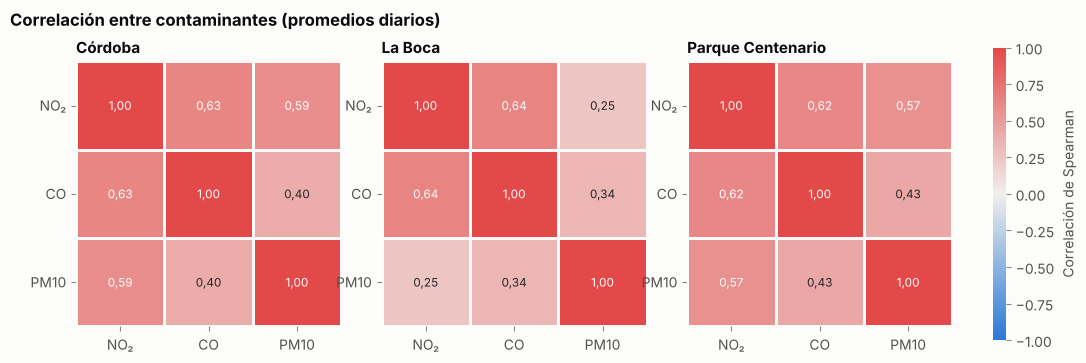

In [36]:
ancho24 = (fact[fact.tiene_dato]
           .pivot_table(index=["id_estacion", "fecha"], columns="id_contaminante", values="valor_masa"))
orden_c = ["no2", "co", "pm10"]
etiquetas_c = ["NO₂", "CO", "PM10"]
cmap_div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ejes = plt.subplots(1, 4, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 0.05]})
barra_ax = ejes[3]
for k, (ax, e) in enumerate(zip(ejes[:3], ORDEN_ESTACIONES)):
    corr = ancho24.loc[e][orden_c].corr(method="spearman")
    corr.index, corr.columns = etiquetas_c, etiquetas_c
    textos = corr.map(lambda v: coma(v, 2))  # coma decimal en las celdas
    sns.heatmap(corr, annot=textos, fmt="", cmap=cmap_div, vmin=-1, vmax=1, square=True, linewidths=2,
                linecolor=SUPERFICIE, cbar=k == 2, cbar_ax=barra_ax if k == 2 else None,
                cbar_kws={"label": "Correlación de Spearman"},
                annot_kws={"fontsize": 8.5}, ax=ax)
    ax.tick_params(axis="y", rotation=0)
    ax.set_title(NOMBRE[e], fontsize=11)
fig.suptitle("Correlación entre contaminantes (promedios diarios)", x=0.07, ha="left", fontweight="bold", fontsize=12)
guardar(fig, "12_correlaciones")
plt.show()

**Qué se concluye:**
- El **NO₂** y el **CO** se mueven juntos de forma moderada en las tres estaciones (0,62 a 0,64): comparten fuente
  (la combustión del tránsito), aunque no del todo (el CO sale sobre todo de los autos a nafta; el NO₂, también del
  diésel).
- El **PM10** es el que menos se mueve con el resto, sobre todo en **La Boca (0,25 con el NO₂ y 0,34 con el CO)**:
  depende también de fuentes regionales, del viento y del polvo. En Centenario y Córdoba acompaña más al NO₂ (0,57 y
  0,59). Correlación no implica causalidad.

## 10. ¿Cuánto condicionan los huecos de datos a las conclusiones? (subpregunta 6)

**Qué se busca:** si un análisis que ignora la calidad de los datos llegaría a una conclusión equivocada.
Ejemplo: "el NO₂ bajó de 2024 a 2026". Se comparan los mismos meses (enero a septiembre) para no mezclar la
estacionalidad.

In [37]:
ene_sep = fact[(fact.id_contaminante == "no2") & fact.tiene_dato
               & (pd.to_datetime(fact.fecha).dt.month <= 9)].copy()
ene_sep["anio"] = pd.to_datetime(ene_sep.fecha).dt.year
por_estacion = ene_sep.pivot_table(index="id_estacion", columns="anio", values="valor_masa", aggfunc="mean")
dias_est = ene_sep.pivot_table(index="id_estacion", columns="anio", values="valor_masa", aggfunc="size")
juntas = ene_sep.groupby("anio")["valor_masa"].mean()
print("Promedio ene-sep por estación (µg/m³):"); print(por_estacion.round(1).to_string())
print("\nDías con dato:"); print(dias_est.to_string())
print("\nLas tres estaciones juntas (µg/m³):", juntas.round(1).to_dict())

Promedio ene-sep por estación (µg/m³):
anio         2024  2025  2026
id_estacion                  
centenario   25.2  28.2  25.3
cordoba      41.8  36.8  36.3
la_boca      58.7  52.0  46.7

Días con dato:
anio         2024  2025  2026
id_estacion                  
centenario     40   260   265
cordoba       209   226   261
la_boca       251   254   230

Las tres estaciones juntas (µg/m³): {2024: 49.0, 2025: 39.0, 2026: 35.6}


Figura guardada: reports/figures/13_ene_sep_composicion.png


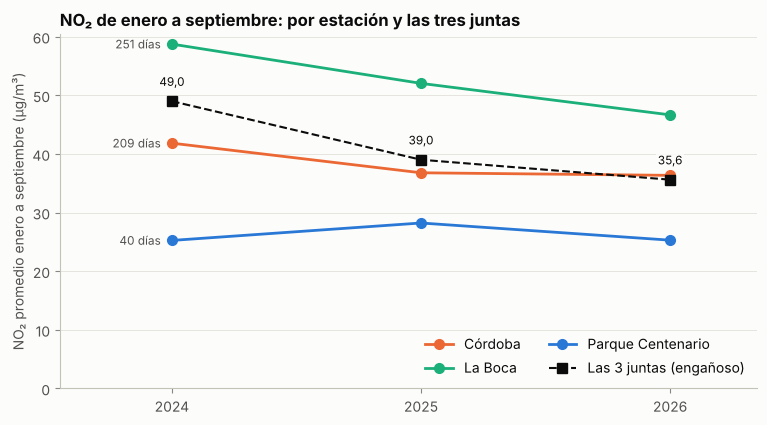

In [38]:
fig, ax = plt.subplots(figsize=(9, 4.6))
anios = [2024, 2025, 2026]
for e in ORDEN_ESTACIONES:
    ax.plot(anios, por_estacion.loc[e, anios], marker="o", markersize=7, color=COLOR_ESTACION[e], label=NOMBRE[e])
    ax.annotate(f"{dias_est.loc[e, 2024]} días", (2024, por_estacion.loc[e, 2024]), xytext=(-8, 0),
                textcoords="offset points", ha="right", va="center", fontsize=8.5, color=TINTA_2)
ax.plot(anios, juntas.loc[anios], marker="s", markersize=7, color=TINTA, linestyle="--", linewidth=1.5,
        label="Las 3 juntas (engañoso)")
for a in anios:
    ax.annotate(coma(juntas.loc[a]), (a, juntas.loc[a]), xytext=(0, 9), textcoords="offset points",
                ha="center", va="bottom", fontsize=8.5, color=TINTA,
                bbox=dict(facecolor=SUPERFICIE, edgecolor="none", alpha=0.85, pad=1))
ax.set_xticks(anios, ["2024", "2025", "2026"])
ax.set_xlim(2023.55, 2026.35)
ax.set_ylim(0, None)
ax.set_ylabel("NO₂ promedio enero a septiembre (µg/m³)")
ax.set_title("NO₂ de enero a septiembre: por estación y las tres juntas")
ax.legend(loc="lower right", ncol=2)
ax.grid(axis="x", visible=False)
guardar(fig, "13_ene_sep_composicion")
plt.show()

**Qué se concluye (subpregunta 6):**
- Juntando las tres estaciones, el NO₂ de enero a septiembre "baja" de **49,0 a 35,6 µg/m³** (26,0 → 18,9 ppb),
  una caída de **27%**. Pero en 2024 **Centenario, la estación más limpia, tiene solo 40 días** (contra 260 o más en los
  otros años): el promedio de 2024 sale inflado porque pesan más La Boca y Córdoba.
- **Por estación**, la baja es menor: **La Boca −20%** y **Córdoba −13%** de 2024 a 2026, y **Centenario no muestra
  tendencia**. Y sin controlar la meteorología (un invierno más ventoso o lluvioso baja el NO₂) no se puede atribuir
  a una mejora real.
- Lección: **los huecos de datos no solo restan precisión, pueden cambiar la conclusión**. Por eso cada indicador
  se informa con su `n` y la regla del 75% deja afuera los años incompletos.

## 11. Contexto: dónde queda el período en la serie larga

**Qué se busca:** ubicar 2024-2026 en la historia de la red. El CSV de BA Data trae datos desde octubre de 2009, así
que con las mismas reglas (valor diario, regla del 75% por año) se arma el promedio anual de 2010 a 2025
(los años 2010-2025 de `agg_anual`). No es parte del análisis principal: es contexto.

In [39]:
# Promedio anual por estación (µg/m³); vacío = año con menos de 75% de días con dato
tabla_ctx = contexto.pivot_table(index="anio", columns=["id_contaminante", "id_estacion"], values="promedio_anual")
tabla_ctx.round(1)

id_contaminante        no2                       pm10                
id_estacion     centenario cordoba la_boca centenario cordoba la_boca
anio                                                                 
2010                   NaN     NaN    47.2        NaN     NaN     NaN
2011                   NaN     NaN    51.0        NaN    40.2    38.8
2012                  33.3    68.1     NaN        NaN     NaN    28.0
2013                   NaN     NaN     NaN       31.4     NaN    26.1
2014                  32.5     NaN     NaN       24.5     NaN     NaN
2015                  30.7    40.7    23.6       26.4    27.6    23.1
2016                  30.0    39.2    19.9       26.6    26.2    27.4
2017                  33.2    41.1    40.4       23.2    25.3    32.5
2018                  31.4    32.1    39.5       21.7    25.1    31.5
2019                  34.7    41.8    40.5       21.4    26.7    30.0
2020                  29.4    44.8     NaN       19.9    19.0     NaN
2021                   NaN     NaN    24.5        NaN     NaN    22.3
2022                   NaN     NaN    31.9       26.9     NaN    34.7
2023                  36.0     NaN     NaN       25.5    27.7    28.6
2024                   NaN    39.3    56.6       21.0    24.5    23.9
2025                  28.6    35.3    50.0       21.1    23.9    23.2

Figura guardada: reports/figures/14_contexto_no2_anual.png


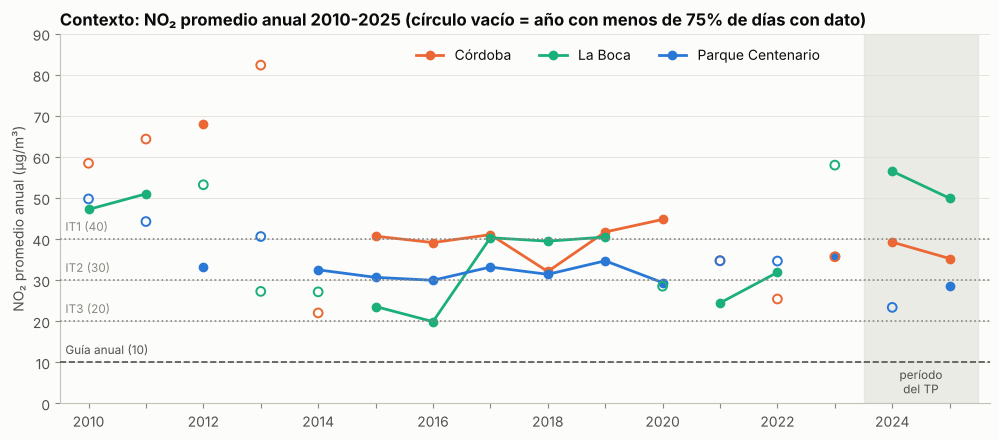

In [40]:
ctx = contexto[contexto.id_contaminante == "no2"]
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.axvspan(2023.5, 2025.5, color=GRILLA, alpha=0.6, zorder=0)
ax.text(2024.5, 0.02, "período\ndel TP", transform=ax.get_xaxis_transform(), ha="center", va="bottom",
        fontsize=8.5, color=TINTA_2)
# Guía y objetivos intermedios anuales del NO2: salen de la tabla de la OMS
for r in guia_oms[(guia_oms.id_contaminante == "no2") & (guia_oms.promedio == "anual")].itertuples():
    es_guia = r.nivel == "AQG"
    linea_guia(ax, r.umbral, f"{'Guía anual' if es_guia else r.nivel} ({r.umbral:.0f})", estilo="--" if es_guia else ":",
               color=TINTA_2 if es_guia else TENUE, lado="izquierda")
for e in ORDEN_ESTACIONES:
    s = ctx[ctx.id_estacion == e].sort_values("anio")
    # años válidos: línea con puntos (se corta en los años no válidos, no se inventa continuidad)
    ax.plot(s.anio, s.promedio_anual, marker="o", markersize=6, color=COLOR_ESTACION[e], label=NOMBRE[e])
    # años con menos de 75% de días: círculo vacío en el valor referencial
    nv = s[~s.es_valido & s.promedio_referencial.notna()]
    ax.scatter(nv.anio, nv.promedio_referencial, s=40, facecolors="none", edgecolors=COLOR_ESTACION[e],
               linewidths=1.4, zorder=3)
ax.set_xticks(range(2010, 2026), [str(a) if a % 2 == 0 else "" for a in range(2010, 2026)])
ax.set_xlim(2009.5, 2025.7)
ax.set_ylim(0, 90)
ax.set_ylabel("NO₂ promedio anual (µg/m³)")
ax.set_title("Contexto: NO₂ promedio anual 2010-2025 (círculo vacío = año con menos de 75% de días con dato)")
ax.legend(loc="upper center", bbox_to_anchor=(0.6, 1), ncol=3)
ax.grid(axis="x", visible=False)
guardar(fig, "14_contexto_no2_anual")
plt.show()

**Qué se concluye (contexto, no es parte del período de estudio):**
- **Córdoba** bajó en la década: de 68 µg/m³ en 2012 a entre 32 y 45 desde 2015. **Parque Centenario** se mantiene
  estable, entre 28 y 36 µg/m³ en los años válidos.
- **La Boca** es la serie más irregular: 47-51 µg/m³ en 2010-2011, 20-24 en 2015-2016, ~40 en 2017-2019, 24-32 en
  2021-2022 y **50-57 en 2024-2025**, el valor más alto de las tres estaciones desde 2012. Los saltos de un año a otro
  no aparecen en las otras estaciones: pueden reflejar cambios de fuentes cercanas, de equipo o de calibración que el
  dataset no documenta. **Es una pregunta para la APrA** y una advertencia para H2: que La Boca sea la peor estación
  es un fenómeno reciente; entre 2015 y 2019, Córdoba la superó en cuatro de cinco años.
- Ningún año de ninguna estación cumple la guía anual de 10 µg/m³: el incumplimiento del período de estudio no es
  nuevo. El **PM10** bajó de 39-40 µg/m³ en 2011 a 21-24 en 2025.
- Es contexto descriptivo: con años incompletos y sin meteorología no se calcula una tendencia.

## 12. Conclusiones exploratorias

**Respuesta a la pregunta:** ninguna estación cumple las guías de la OMS para el NO₂, pero **Parque Centenario y
Córdoba están en los escalones intermedios** (IT2 e IT1 en el promedio anual) y **La Boca no alcanza ni el primero**.
El PM10 está más cerca de la guía y el CO no es un problema.

| | NO₂ | PM10 | CO |
|---|---|---|---|
| Escalón OMS anual (últimos 12 meses) | IT2 (Centenario), IT1 (Córdoba), > IT1 (La Boca) | IT3 en las tres | — |
| Días que cumplen el IT2 diario (NO₂: 50 µg/m³) | 98,5% (Centenario), 87,6% (Córdoba), 50,0% (La Boca) | — | — |
| % de días sobre la guía de 24 h | 55% (Centenario) a 95% (La Boca) | 2% a 4% | 0% |
| Promedio de los últimos 12 meses vs. guía anual | 2,6 a 4,6 veces | 1,4 a 1,8 veces | sin guía anual |
| P99 anual vs. guía de 24 h | 1,7 a 4,2 veces | 1,0 a 1,4 veces | < 0,4 veces |

**Hipótesis:**
- **H1 se sostiene:** el NO₂ es el contaminante más crítico. Supera la guía diaria el 55% a 95% de los días, contra
  2% a 4% del PM10 y 0% del CO; su promedio anual está 2,6 a 4,6 veces sobre la guía (PM10: 1,4 a 1,8) y su P99,
  1,7 a 4,2 veces (PM10: 1,0 a 1,4; CO: menos de 0,4).
- **H2 no se sostiene:** la estación más comprometida en NO₂ no es Córdoba, la de tránsito intenso, sino **La Boca**,
  con todos los indicadores (% de días, promedio anual, P99, racha de 254 días con dato); es la única por encima del
  objetivo intermedio menos exigente (IT1). Córdoba queda segunda. La Boca tiene flujo vehicular medio-bajo pero
  fuentes fijas cercanas, es la que menos baja el domingo y tiene el piso de madrugada más alto: el tránsito de la
  avenida no explica todo. La serie larga agrega que es un fenómeno reciente.
- **H3 se sostiene a medias:** domingos y feriados el NO₂ baja entre 16% y 26%, y el perfil horario muestra que la
  diferencia está en las horas pico; pero en La Boca el 90% de los domingos sigue por encima de la guía.

**Otros hallazgos:** fuerte estacionalidad del NO₂ (invierno ~1,8 veces el verano en La Boca); los días más extremos
son episodios compartidos por varias estaciones; la aparente baja de 2024 a 2026 está inflada por los huecos de
datos; en la serie larga, Córdoba bajó desde 2012 y La Boca subió en 2023-2025.

**Limitaciones:**
- **Solo 3 estaciones**: no representan a toda la Ciudad (no hay estaciones en el sur-oeste ni en el norte).
- **Huecos de datos**, en especial el NO₂ de Centenario en 2024; los indicadores anuales con menos de 75% de días
  no se calculan.
- **2026 es parcial** (enero a septiembre): se compara con los últimos 12 meses, no con el año calendario.
- **Sin control meteorológico**: las diferencias entre períodos o estaciones del año pueden deberse al clima.
- La guía de 24 h es estadísticamente un **P99 anual**; el "% de días" es una simplificación para comunicar.
- Los datos de entrada son los **valores horarios de BA Data**: el NO₂ es horario, pero el CO y el PM10 vienen como
  **promedios móviles** (8 y 24 h), así que su serie horaria no se usa como tal. La fuente tiene **huecos de
  exportación** (días cortados al mediodía, algunos días sin filas) que sí tienen dato en los informes en PDF de la
  APrA; el TP no los rellena.
- La conversión de ppb a µg/m³ supone 25 °C y 1 atm (convención de la OMS).